<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/06_Android_Malware_Detection/HybridQCNN_ExplainableAndroidMalware_Mercaldo2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum CNN with Grad-CAM for Android malware images: Mercaldo et al. (2022) step by step

This notebook re-implements, runs and checks the method of

> Francesco Mercaldo, Giovanni Ciaramella, Giacomo Iadarola, Marco Storto, Fabio Martinelli and Antonella Santone,
> "Towards Explainable Quantum Machine Learning for Mobile Malware Detection and Classification",
> *Applied Sciences* 12(23), 12025, 2022. https://doi.org/10.3390/app122312025

The paper converts the `.dex` code of 8,446 Android apps (six malware families plus legitimate "Trusted" apps) into grey-scale pictures and compares
seven classical image classifiers with **two quantum models**: a **Hybrid-QCNN** (a quantum convolution in front of a small CNN) and a **fully quantum
neural network (QNN)** of Farhi and Neven. Its second contribution is **explainability**: Grad-CAM heat maps show which part of the picture drove a prediction.
This notebook is the extended journal version of the ARES 2022 paper that is reproduced in `HybridQCNN_AndroidMalwareImages_Ciaramella2022.ipynb`; what is new here
(and what this notebook concentrates on) is the **fully quantum QNN**, the **extra classical baselines** (MobileNet, VGG19, EfficientNet) and, above all, **Grad-CAM, which we quantify** instead of only showing pictures.

**What the notebook does.**
1. Downloads a *public* image set made from real Android APKs (**MalVis**, Hugging Face `salehmak/MalVis`), converts it to grey-scale squares of 110x110, 25x25 and 4x4 pixels (the three sizes of the paper's Table 1) and keeps seven classes (benign + six malware categories).
2. Builds the **quantum convolution layer** and the **17-qubit Farhi-Neven QNN** in PennyLane, draws both circuits, and proves with Qiskit that the simulated circuits do what the drawings say.
3. Trains the paper's ten model rows (AlexNet, Standard-CNN at 110 and 25 pixels, VGG16, MobileNet, VGG19, EfficientNet at two sizes, Hybrid-QCNN, QNN) with the epochs, batch sizes and learning rates of its Table 1.
4. Adds **classical twins** that isolate what the quantum parts contribute (a trainable and a frozen classical 2x2 convolution instead of the quantum one; a one-number bottleneck instead of the QNN's one-qubit read-out) and a random forest on the same pixels.
5. Applies **Grad-CAM** to the best classical model and to the Hybrid-QCNN and **tests the paper's explanation claims numerically** (deletion test, same-family versus different-family agreement, model-randomisation sanity check, wrong-versus-right predictions).
6. Prints the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned packages; if Colab asks you to restart the session, do so and run all again.
No GPU and no quantum-hardware account are needed. The first run downloads the images one by one from Hugging Face (about 165 kB each; a few minutes in `FAST_MODE`, much longer in the full run) and four small ImageNet weight files (about 250 MB, deleted afterwards).
Gated data are not involved: MalVis is public. If you have a Hugging Face token it is read only from Colab Secrets (`HF_TOKEN`) or the environment and never printed.

**Important caveat, read first.** The authors' 8,446 Android images are not public (their web service at `ocs.iit.cnr.it` is offline and no data link is given). The closest public substitute with the same modality
(bytes of real Android applications drawn as a picture and classified by malware category) is **MalVis** (Saleh et al., 2025). MalVis labels *categories* (adware, trojan, ...) rather than the paper's six *families*, and its pictures are colour-coded
by the MalVis authors (we convert them to grey-scale to match the paper's input). All absolute numbers below therefore belong to a different and, as it turns out, much harder data set; the notebook tests the **paper's claims about architectures and explanations**, not its exact accuracies.

**Runtime.** `FAST_MODE = True`: 40 images per class and the two expensive 110x110 networks shortened to 8 and 12 epochs, every other row at the paper's epoch count; about 10 to 15 minutes on an idle CPU thread plus the image download. `FAST_MODE = False` (the published run, see the run time printed at the end): **every row at the epoch count of the paper's Table 1**, 120 images per class (840 pictures; the paper has 8,446), one stratified split; about 1.5 hours on one CPU thread (the published run: 94 minutes on a shared machine), dominated by the image download, the VGG16/VGG19 feature extraction and the two 110x110 networks. For error bars set `N_SEEDS = 3`; for a closer-to-paper sample raise `N_PER_CLASS`.

## The paper in one page

**Problem.** Decide whether an Android app is malicious and, if so, which family it belongs to, from a picture of its code; then show *where* in the picture the decision came from.

**Decision.** 7-class classification: Airpush, Dowgin, FakeInst, Fusob, Jisut, Mecor (malware families) and Trusted (legitimate apps).

**Data.** 8,446 apps: Airpush 1,170, Dowgin 763, FakeInst 2,129, Fusob 1,275, Jisut 550, Mecor 1,499, Trusted 1,060; labels checked with VirusTotal (60+ engines). Only `classes.dex` is converted into a grey-scale PNG.
Split 80/20 into training (6,759) and test (1,687); 1,351 training apps form a validation folder.

**Models and settings (Table 1).**

| Model | Image | Batch | Epochs | Learning rate | Training time |
|---|---|---|---|---|---|
| AlexNet | 110x1 | 32 | 50 | 0.001 | 0:47:14 |
| Standard-CNN (Listing 1) | 110x1 | 32 | 50 | 0.001 | 1:11:54 |
| Standard-CNN | 25x3 | 64 | 20 | 0.001 | 0:01:34 |
| VGG16 (ImageNet conv. weights kept, dense head trained) | 110x3 | 32 | 25 | 0.001 | 2:56:45 |
| MobileNet | 110x3 | 64 | 25 | 0.001 | 0:22:45 |
| VGG19 | 110x3 | 64 | 25 | 0.001 | 3:35:56 |
| EfficientNet | 110x3 | 64 | 25 | 0.001 | 0:36:25 |
| EfficientNet | 25x3 | 64 | 20 | 0.001 | 0:07:26 |
| Hybrid-QCNN (Listing 2) | 25x1 | 32 | 20 | 0.010 | 1 day 5:39:14 |
| QNN (Listing 3) | 4x1 | 64 | 10 | 0.010 | 0:10:34 |

**Hybrid-QCNN (Listing 2).** `QConv(filter_size=2, depth=8, relu)` -> `Conv2D(16, 2x2, relu)` -> `Flatten` -> `Dense(32, relu)` -> `Dense(7, softmax)`; the quantum layer is simulated in TensorFlow Quantum.
**QNN (Listing 3).** `PQC(model_circuit, readout)` -> `Dense(7, softmax)`; the circuit is the Farhi-Neven classifier: the 4x4 image is a 16-bit string, each layer applies one two-qubit gate between every data qubit and a single read-out qubit.

**Claims (Table 2, test set).**

| Model | Loss | Accuracy | Precision | Recall | F-measure | AUC |
|---|---|---|---|---|---|---|
| AlexNet | 0.435 | 0.912 | 0.920 | 0.908 | 0.914 | 0.983 |
| Standard-CNN (110x3) | 0.205 | 0.970 | 0.972 | 0.970 | 0.971 | 0.993 |
| Standard-CNN (25x3) | 0.260 | 0.915 | 0.927 | 0.910 | 0.919 | 0.993 |
| VGG16 | 0.182 | 0.952 | 0.959 | 0.949 | 0.954 | 0.993 |
| MobileNet | 0.124 | 0.966 | 0.969 | 0.963 | 0.966 | 0.996 |
| VGG19 | 0.187 | 0.951 | 0.953 | 0.947 | 0.950 | 0.994 |
| EfficientNet (110x3) | 23.738 | 0.065 | 0.065 | 0.065 | 0.065 | 0.455 |
| EfficientNet (25x3) | 2.343 | 0.251 | 0.135 | 0.022 | 0.038 | 0.535 |
| Hybrid-QCNN | 1.045 | 0.905 | 0.905 | 0.903 | 0.904 | 0.962 |
| QNN | 1.584 | 0.413 | 0.623 | 0.103 | 0.176 | 0.762 |

Table 3 gives per-family accuracy / precision / recall / F-measure / AUC for the Standard-CNN and the Hybrid-QCNN (Hybrid F-measures: Airpush 0.824, Dowgin 0.699, FakeInst 0.982, Fusob 0.994, Jisut 0.953, Mecor 0.996, Trusted 0.729).

**Explanation claims (Section 3.4 and 5, Figures 8 to 11).** (i) Grad-CAM highlights the part of the image that led to the decision; (ii) samples of one family share a payload, so their heat maps should highlight the same area, and different families different areas;
(iii) a wrong prediction shows a different highlighted area (Figures 9 and 11); (iv) for an Airpush sample the Standard-CNN highlights the top of the picture, for Hybrid-QCNN samples the highlighted areas are small and central.
Other claims: the Standard-CNN is the best model; the Hybrid-QCNN is the best quantum model and beats EfficientNet at the same 25x25 size; the QNN does poorly; the Hybrid-QCNN needs more than a day of training.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | 8,446 apps, `classes.dex` as grey PNG, not public | **MalVis** (Android APKs drawn as 256x256 colour pictures, public on Hugging Face `salehmak/MalVis`), converted to grey (ITU-R 601 luma); `# CHOICE` |
| Classes | 6 families + Trusted | 7 classes: `benign` (plays "Trusted"), `adware`, `addisplay`, `exploit`, `riskware`, `spyware`, `trojan`. MalVis labels categories, not families. The classes `spr` and `unknown` are not used because their meaning is not documented; `# CHOICE` |
| Sample size | 8,446 | `N_PER_CLASS` random images per class (class-balanced; 40 in `FAST_MODE`, 150 in the full run), because the download is slow and the quantum simulation costly; `# CHOICE` |
| Split | 80/20 train/test, 1,351 validation images taken from the training folder | stratified 80/20, then 20 % of the training part as validation (monitoring only, final weights are evaluated); re-drawn for every seed |
| Image sizes | 110x110 (classical), 25x25 (hybrid, and the small classical rows), 4x4 (QNN) | the same, resized from the 256x256 originals by box averaging; the paper's "25x3" rows use 25x25x1 for the Standard-CNN (as the text says) and 25 pixels replicated to 3 channels and resized to 32x32 for EfficientNet (Keras requires at least 32); `# CHOICE` |
| Quantum convolution | `QConv(filter_size=2, depth=8)` in TensorFlow Quantum; circuit, stride, trainability not given | PennyLane: 2x2 patch -> 4 qubits, `RY(pi x)` encoding, two layers of `RX, RZ` + CNOT ring, **8 read-outs** (4 single-qubit `<Z>` and 4 neighbour `<ZZ>`) = `depth=8`; stride 2; parameters drawn once from `SEED` and **frozen** (the layer is a fixed feature extractor, computed once); `# CHOICE` |
| QNN | Farhi-Neven circuit on a 4x4 image, TFQ `PQC` | 16 data qubits + 1 read-out qubit: image thresholded at the training median -> bit string, read-out in `|->`, one `XX` layer then one `ZZ` layer (32 trainable angles, uniform in 0..2pi), `<Z>` of the read-out after a Hadamard, then `Dense(1 -> 7)`. Trained with a closed-form simulation that is **asserted equal** to the PennyLane and Qiskit circuits; `# CHOICE` |
| Classical rows | Keras models | PyTorch for AlexNet (half-width, `# CHOICE`) and the Standard-CNN (Listing 1 layer by layer); **Keras Applications ImageNet weights** (no-top) for VGG16, VGG19, MobileNet, EfficientNet-B0, kept frozen as the paper describes for VGG16, followed by a trained head `Dense(256) -> Dropout(0.5) -> Dense(7)` on standardised features; `# CHOICE` |
| Optimiser, loss | not given | Adam with the learning rates of Table 1, cross-entropy; the classical twins pick 0.001 or 0.01 on the validation split; `# CHOICE` |
| Metrics | loss, accuracy, precision, recall, F, AUC | Same, with Keras semantics for precision/recall/AUC (class probability above 0.5, micro-averaged one-vs-rest), because the paper's QNN row (accuracy 0.413 but recall 0.103) is impossible with arg-max averages; macro-F1 is shown as well; `# CHOICE` |
| Grad-CAM | pictures only | Grad-CAM on the last convolution of the Standard-CNN and of the Hybrid-QCNN, **plus numbers**: deletion test, same-/different-family agreement, randomised-model check, wrong-versus-right, high-activation area |
| Seeds, repeats | one run | `SEED = 42`, mean +- std over splits |
| Hardware times | Xeon, TFQ, 29 h for the Hybrid | 1 CPU thread; our quantum layer is pre-computed once, so the multi-day cost is **not** reproduced |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and tensorflow.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "pennylane_lightning", "qiskit", "huggingface_hub", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0" "qiskit==2.5.2" huggingface_hub pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane / qiskit already present; skipping pip install.")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
if importlib.util.find_spec("tensorflow") is None:
    %pip install -q tensorflow-cpu

pennylane / qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False       # True: reduced run (40 images per class, 110x110 nets shortened). False: the paper's epochs for every row and 120 images per class (about 1 to 1.5 hours on one CPU thread).
SEED        = 42         # CHOICE: the paper gives no seed
IBM_TOKEN   = ""         # not used: everything runs on exact simulators (no real hardware)
N_THREADS   = 1          # torch / TensorFlow / BLAS threads (one CPU thread keeps the notebook polite on a shared machine)

# Data -------------------------------------------------------------------------------------------------------------
HF_REPO      = "salehmak/MalVis"                  # public Hugging Face dataset of Android APK images
DATA_DIR     = "data"                             # cache folder (images are cached here; to work offline put malvis_cache.npz here)
# CHOICE: benign plays the paper's "Trusted"; six malware categories play its six families. 'spr' and 'unknown' are undocumented -> unused.
CLASSES      = ["benign", "adware", "addisplay", "exploit", "riskware", "spyware", "trojan"]
DISPLAY      = {"benign": "Trusted", "adware": "Adware", "addisplay": "AdDisplay", "exploit": "Exploit",
                "riskware": "Riskware", "spyware": "Spyware", "trojan": "Trojan"}
N_PER_CLASS  = 40 if FAST_MODE else 120           # images per class (class-balanced random draw); the paper has 8,446 images in total. Raise it for a closer-to-paper run (the download is the bottleneck).
N_SEEDS      = 1                                  # independent stratified splits (mean +- std); set 3 for error bars (about 3x the training time of the two 110x110 networks)
TEST_SIZE    = 0.2                                # paper: 80 / 20
VAL_SIZE     = 0.2                                # share of the training part used as validation (paper: 1351 of 6759)
S_BIG, S_SMALL, S_QNN = 110, 25, 4                # paper Table 1 image sizes

# Training (Table 1 of the paper): name -> (image size / input, batch, epochs, learning rate) --------------------------
PAPER_TABLE1 = {
    "AlexNet":              dict(batch=32, epochs=50, lr=1e-3),
    "Standard-CNN (110x1)": dict(batch=32, epochs=50, lr=1e-3),
    "Standard-CNN (25x1)":  dict(batch=64, epochs=20, lr=1e-3),
    "VGG16":                dict(batch=32, epochs=25, lr=1e-3),
    "MobileNet":            dict(batch=64, epochs=25, lr=1e-3),
    "VGG19":                dict(batch=64, epochs=25, lr=1e-3),
    "EfficientNet (110x3)": dict(batch=64, epochs=25, lr=1e-3),
    "EfficientNet (25x3)":  dict(batch=64, epochs=20, lr=1e-3),
    "Hybrid-QCNN":          dict(batch=32, epochs=20, lr=1e-2),
    "QNN":                  dict(batch=64, epochs=10, lr=1e-2),
}
# FAST_MODE shortens only the two expensive 110x110 networks; every other row keeps the paper's epoch count (they train on cached features or on 25x25 / 4x4 inputs and cost seconds)
FAST_EPOCHS = {"AlexNet": 8, "Standard-CNN (110x1)": 12, "Standard-CNN (25x1)": 20, "VGG16": 25, "MobileNet": 25, "VGG19": 25,
               "EfficientNet (110x3)": 25, "EfficientNet (25x3)": 20, "Hybrid-QCNN": 20, "QNN": 10}
TRAIN_CFG = {k: dict(v, epochs=(FAST_EPOCHS[k] if FAST_MODE else v["epochs"])) for k, v in PAPER_TABLE1.items()}

# Quanvolution layer (CHOICE: the paper gives only filter_size=2, depth=8) ------------------------------------------------
Q_FILTER, Q_STRIDE, Q_LAYERS = 2, 2, 2            # 2x2 patch -> 4 qubits; non-overlapping; 2 variational layers

# Explainability tests --------------------------------------------------------------------------------------------------
N_CAM_DELETION = 40 if FAST_MODE else 120         # correctly classified test images used in the deletion test
DELETE_FRACTIONS = [0.0, 0.05, 0.10, 0.20, 0.30, 0.50]
N_PERM = 200 if FAST_MODE else 1000               # permutations for the same-/different-family test

# Environment for a polite single-threaded run (must be set before torch / TensorFlow are imported)
import os
for v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[v] = str(N_THREADS)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.makedirs(DATA_DIR, exist_ok=True)
os.environ["KERAS_HOME"] = os.path.abspath(os.path.join(DATA_DIR, "keras_home"))   # ImageNet weight files land here and are deleted after use
print("FAST_MODE =", FAST_MODE, "| N_PER_CLASS =", N_PER_CLASS, "| N_SEEDS =", N_SEEDS)
print("epochs:", {k: v["epochs"] for k, v in TRAIN_CFG.items()})

FAST_MODE = False | N_PER_CLASS = 120 | N_SEEDS = 1
epochs: {'AlexNet': 50, 'Standard-CNN (110x1)': 50, 'Standard-CNN (25x1)': 20, 'VGG16': 25, 'MobileNet': 25, 'VGG19': 25, 'EfficientNet (110x3)': 25, 'EfficientNet (25x3)': 20, 'Hybrid-QCNN': 20, 'QNN': 10}


In [3]:
import io, time, warnings, math, glob, shutil, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 140); pd.set_option("display.max_columns", 40)

import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import qiskit
import sklearn
import scipy
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, log_loss, confusion_matrix,
                             precision_recall_fscore_support)

torch.set_num_threads(N_THREADS)
try:
    torch.set_num_interop_threads(1)
except Exception:
    pass
torch.manual_seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)
N_CLASSES = len(CLASSES)
NAMES = [DISPLAY[c] for c in CLASSES]
CLASS_COLORS = plt.get_cmap("tab10")(np.arange(N_CLASSES))
T_NOTEBOOK_START = time.time()

# Hugging Face token (only needed for a gated or rate-limited mirror; MalVis itself is public). Read from the environment / Colab Secrets, never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
HF_HEADERS = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}

print("torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("Hugging Face token available:", HF_TOKEN is not None)

torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
Hugging Face token available: True


## 1. The data: Android applications drawn as grey-scale pictures

The paper's idea (Section 2.1) is to read an application file as a long list of bytes, cut the list into rows and show each byte as a pixel. Apps of one malware family share code, so their pictures share textures, and a convolutional
network can learn those textures. The authors used the `classes.dex` of each APK. Their pictures are not published.

**Public substitute: MalVis** (Saleh et al., 2025, "MalVis: a large-scale image-based framework and dataset for Android malware classification"). It holds about 83,000 PNG pictures of 256x256 pixels, one folder per
label (nine malware categories and `benign`), generated from real Android applications. The pictures are **colour-coded** by the MalVis authors (a different byte-to-pixel mapping than the paper's grey values), so we convert each picture to grey-scale by luma (`# CHOICE`),
which gives the same one-channel input as the paper. Labels are *categories*, not families, and the data set is read from the Hugging Face file list, so the class sizes printed below are the **real** MalVis class sizes.

Downloading is slow (every picture is a separate 165 kB file), so the notebook draws `N_PER_CLASS` pictures per class with a seeded random draw and caches the three reduced versions it needs (110x110, 25x25 and 4x4) in `DATA_DIR`.
A bigger run re-uses everything that is already cached.

In [4]:
from huggingface_hub import HfApi
t0 = time.time()
CACHE_PATH = os.path.join(DATA_DIR, "malvis_cache.npz")

# 1. the real file list (all pictures of the chosen classes)
all_files = HfApi().list_repo_files(HF_REPO, repo_type="dataset", token=HF_TOKEN)
FILES = {c: sorted(f for f in all_files if f.startswith(c + "/") and f.endswith(".png")) for c in CLASSES}
TOTAL_PER_CLASS = {c: len(v) for c, v in FILES.items()}
print("pictures in the repository per chosen class:", TOTAL_PER_CLASS)

# 2. seeded class-balanced draw (the first N of a fixed permutation, so a bigger N contains a smaller N)
sel = []
for ci, c in enumerate(CLASSES):
    perm = np.random.default_rng(SEED + ci).permutation(len(FILES[c]))[:N_PER_CLASS]
    sel += [(FILES[c][i], ci) for i in perm]

# 3. cache: name -> (110x110, 25x25, 4x4 grey versions of the 256x256 original)
cache = {}
if os.path.exists(CACHE_PATH):
    z = np.load(CACHE_PATH, allow_pickle=False)
    cache = {n: (a, b, c) for n, a, b, c in zip(z["names"], z["a110"], z["a25"], z["a4"])}
    print("cache loaded:", len(cache), "pictures")

def fetch(name):
    """Download one MalVis picture and return its grey-scale 110x110, 25x25 and 4x4 versions (box-averaged from 256x256)."""
    err = None
    for _ in range(4):
        try:
            r = requests.get(f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{name}", headers=HF_HEADERS, timeout=90)
            r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)).convert("L")          # CHOICE: ITU-R 601 luma of the colour picture
            return tuple(np.asarray(im.resize((s, s), Image.Resampling.BOX), dtype=np.uint8) for s in (S_BIG, S_SMALL, S_QNN))
        except Exception as e:
            err = e; time.sleep(1.0)
    raise RuntimeError(f"could not download {name}: {err}")

todo = [n for n, _ in sel if n not in cache]
print(f"{len(sel)} pictures needed, {len(todo)} to download" + (" (this takes a while: ~1 s per picture, 32 in parallel)" if todo else ""))
if todo:
    done = 0
    with ThreadPoolExecutor(max_workers=32) as ex:
        for n, res in zip(todo, ex.map(fetch, todo)):
            cache[n] = res; done += 1
            if done % 100 == 0: print(f"  {done}/{len(todo)} downloaded ({time.time() - t0:.0f} s)")
    names_arr = np.array(list(cache.keys()))
    np.savez_compressed(CACHE_PATH, names=names_arr, a110=np.stack([cache[n][0] for n in names_arr]),
                        a25=np.stack([cache[n][1] for n in names_arr]), a4=np.stack([cache[n][2] for n in names_arr]))

SEL_NAMES = [n for n, _ in sel]
X110 = np.stack([cache[n][0] for n in SEL_NAMES]); X25 = np.stack([cache[n][1] for n in SEL_NAMES]); X4 = np.stack([cache[n][2] for n in SEL_NAMES])
y = np.array([c for _, c in sel])
print(f"{len(y)} images ready in {time.time() - t0:.0f} s | X110 {X110.shape} | X25 {X25.shape} | X4 {X4.shape}")
print("cache file size: %.1f MB" % (os.path.getsize(CACHE_PATH) / 1e6))

pictures in the repository per chosen class: {'benign': 10000, 'adware': 10000, 'addisplay': 9995, 'exploit': 6760, 'riskware': 9993, 'spyware': 6259, 'trojan': 9993}
cache loaded: 280 pictures
840 pictures needed, 560 to download (this takes a while: ~1 s per picture, 32 in parallel)


  100/560 downloaded (102 s)


  200/560 downloaded (147 s)


  300/560 downloaded (194 s)


  400/560 downloaded (245 s)


  500/560 downloaded (297 s)


840 images ready in 325 s | X110 (840, 110, 110) | X25 (840, 25, 25) | X4 (840, 4, 4)
cache file size: 9.3 MB


## Dataset Exploration and Visualisation

Before any model, look at the real data: how many pictures there are per class, what they look like, and whether the classes can be told apart at all. Everything below uses **real MalVis pictures with their real labels**; nothing is generated.
The scatter plots project the pictures to two dimensions with a PCA that is **fitted on the training split only**.

dataset shape (images, height, width): (840, 110, 110) (110x110) | (840, 25, 25) (25x25) | (840, 4, 4) (4x4)
features per image: 110*110 = 12100 grey pixels; 25*25 = 625 ; 4*4 = 16
pixel value range: 0 to 252 | mean 67.4 (0 = black, 255 = white)
original labels (MalVis folder names): ['benign', 'adware', 'addisplay', 'exploit', 'riskware', 'spyware', 'trojan']
sampled class counts: {'benign': 120, 'adware': 120, 'addisplay': 120, 'exploit': 120, 'riskware': 120, 'spyware': 120, 'trojan': 120}
split sizes: train 537 | validation 135 | test 168


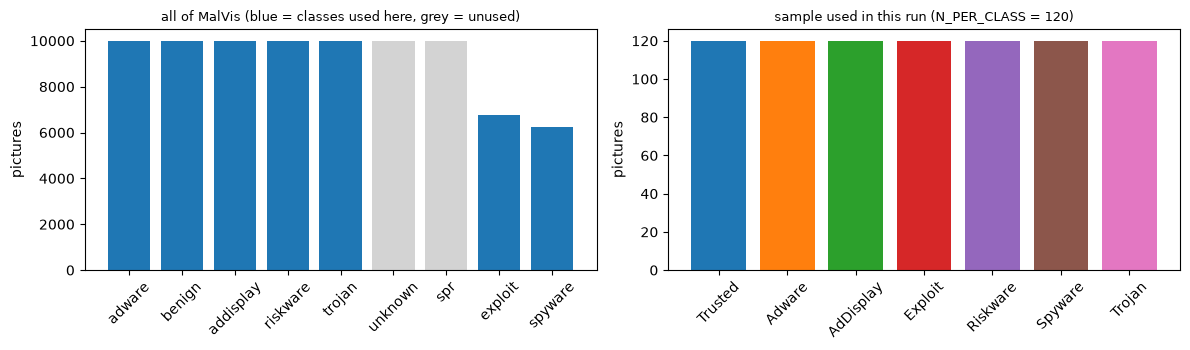

In [5]:
def make_split(seed):
    """Stratified 80/20 train+validation / test split; then 20 % of the training part as validation. All indices refer to the arrays X110, X25, X4, y."""
    idx = np.arange(len(y))
    idx_trv, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=y, random_state=seed)
    idx_tr, idx_va = train_test_split(idx_trv, test_size=VAL_SIZE, stratify=y[idx_trv], random_state=seed)
    return idx_tr, idx_va, idx_te

idx_tr, idx_va, idx_te = make_split(SEED)
print("dataset shape (images, height, width):", X110.shape, "(110x110) |", X25.shape, "(25x25) |", X4.shape, "(4x4)")
print("features per image: 110*110 =", 110 * 110, "grey pixels; 25*25 =", 25 * 25, "; 4*4 =", 16)
print("pixel value range:", X110.min(), "to", X110.max(), "| mean %.1f" % X110.mean(), "(0 = black, 255 = white)")
print("original labels (MalVis folder names):", CLASSES)
print("sampled class counts:", dict(zip(CLASSES, np.bincount(y, minlength=N_CLASSES).tolist())))
print("split sizes: train", len(idx_tr), "| validation", len(idx_va), "| test", len(idx_te))

# class distribution of the REAL data set (every MalVis folder) next to the sample used here
from collections import Counter
folder_counts = Counter(f.split("/")[0] for f in all_files if f.endswith(".png"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
cats = sorted(folder_counts, key=folder_counts.get, reverse=True)
axes[0].bar(cats, [folder_counts[c] for c in cats], color=["tab:blue" if c in CLASSES else "lightgrey" for c in cats])
axes[0].set_title("all of MalVis (blue = classes used here, grey = unused)", fontsize=9); axes[0].set_ylabel("pictures"); axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(NAMES, np.bincount(y, minlength=N_CLASSES), color=CLASS_COLORS)
axes[1].set_title(f"sample used in this run (N_PER_CLASS = {N_PER_CLASS})", fontsize=9); axes[1].set_ylabel("pictures"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

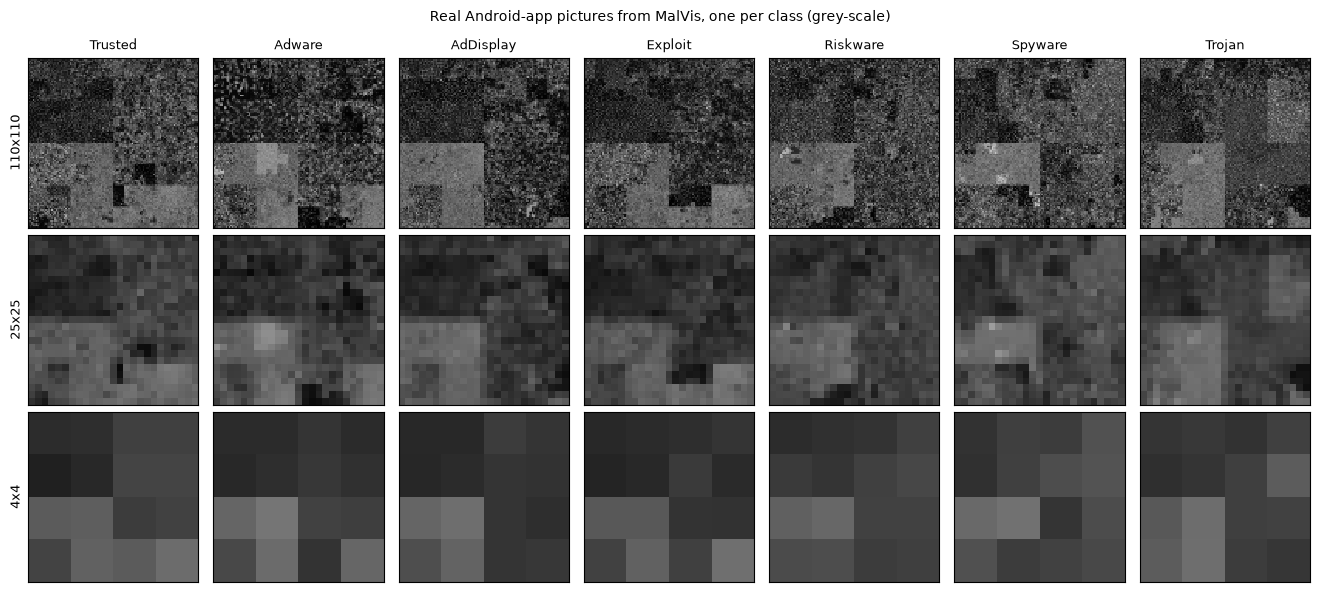

In [6]:
# Counterpart of the paper's Figure 1: real pictures of the classes, at the three resolutions of Table 1
fig, axes = plt.subplots(3, N_CLASSES, figsize=(1.9 * N_CLASSES, 6.0))
for ci in range(N_CLASSES):
    k = np.where(y == ci)[0][0]
    for r, (arr, lab) in enumerate([(X110, "110x110"), (X25, "25x25"), (X4, "4x4")]):
        axes[r, ci].imshow(arr[k], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        axes[r, ci].set_xticks([]); axes[r, ci].set_yticks([])
        if r == 0: axes[r, ci].set_title(NAMES[ci], fontsize=9)
        if ci == 0: axes[r, ci].set_ylabel(lab, fontsize=9)
plt.suptitle("Real Android-app pictures from MalVis, one per class (grey-scale)", fontsize=10); plt.tight_layout(); plt.show()

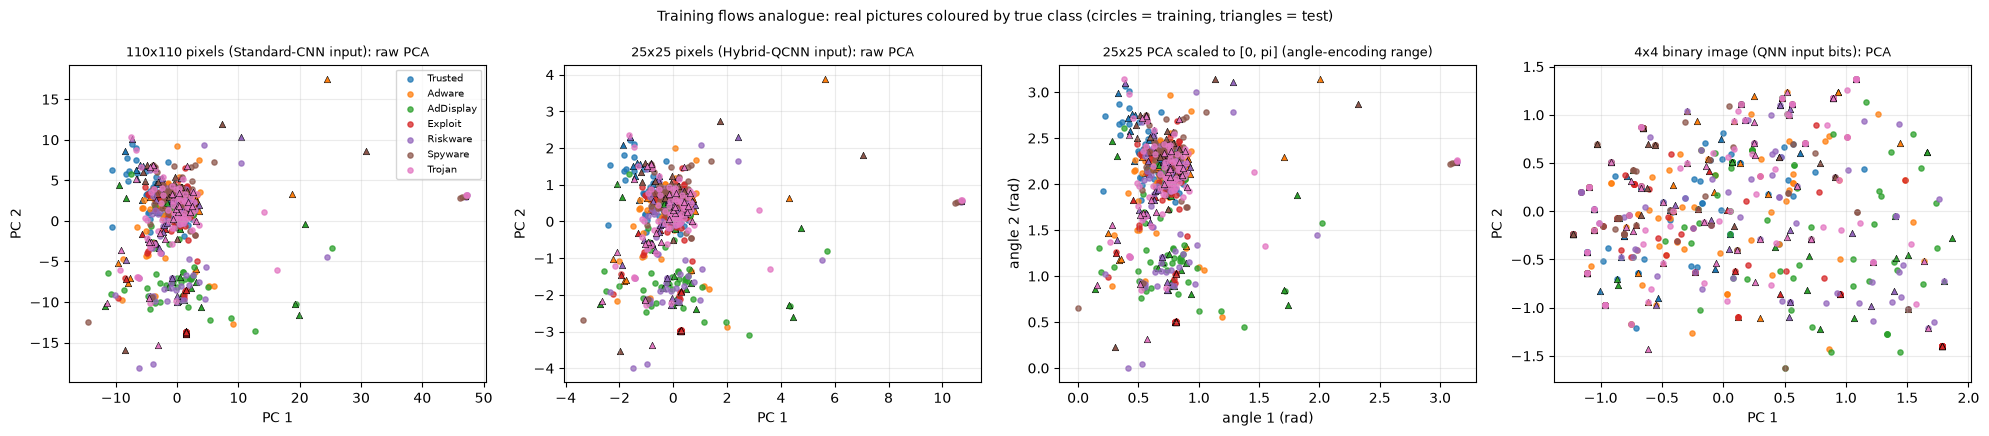

explained variance of the first two components (110x110): 0.30, (25x25): 0.48


In [7]:
# 2-D scatter of the real pictures coloured by ground-truth class (PCA fitted on the training split only)
def scatter_panel(ax, Ztr, Zte, title, xlabel="PC 1", ylabel="PC 2"):
    for ci in range(N_CLASSES):
        m = y[idx_tr] == ci
        ax.scatter(Ztr[m, 0], Ztr[m, 1], s=14, color=CLASS_COLORS[ci], alpha=0.75, label=NAMES[ci])
        m = y[idx_te] == ci
        ax.scatter(Zte[m, 0], Zte[m, 1], s=22, color=CLASS_COLORS[ci], marker="^", edgecolor="k", linewidth=0.4)
    ax.set_title(title, fontsize=9); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=0.25)

flat = lambda a, idx, s=None: a[idx].reshape(len(idx), -1).astype(np.float64) / 255.0
pca110 = PCA(n_components=2, random_state=SEED).fit(flat(X110, idx_tr))
Z110_tr, Z110_te = pca110.transform(flat(X110, idx_tr)), pca110.transform(flat(X110, idx_te))
pca25 = PCA(n_components=2, random_state=SEED).fit(flat(X25, idx_tr))
Z25_tr, Z25_te = pca25.transform(flat(X25, idx_tr)), pca25.transform(flat(X25, idx_te))
ang = MinMaxScaler((0, np.pi)).fit(Z25_tr)                    # angle encoding: scale to [0, pi] with training statistics, clip the test points
A25_tr, A25_te = ang.transform(Z25_tr), np.clip(ang.transform(Z25_te), 0, np.pi)
thr_demo = np.median(X4[idx_tr])                                # QNN input: 16 bits (training median threshold)
B_tr, B_te = (X4[idx_tr] > thr_demo).reshape(len(idx_tr), -1).astype(float), (X4[idx_te] > thr_demo).reshape(len(idx_te), -1).astype(float)
pcaB = PCA(n_components=2, random_state=SEED).fit(B_tr)
ZB_tr, ZB_te = pcaB.transform(B_tr), pcaB.transform(B_te)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.4))
scatter_panel(axes[0], Z110_tr, Z110_te, "110x110 pixels (Standard-CNN input): raw PCA")
scatter_panel(axes[1], Z25_tr, Z25_te, "25x25 pixels (Hybrid-QCNN input): raw PCA")
scatter_panel(axes[2], A25_tr, A25_te, "25x25 PCA scaled to [0, pi] (angle-encoding range)", "angle 1 (rad)", "angle 2 (rad)")
scatter_panel(axes[3], ZB_tr, ZB_te, "4x4 binary image (QNN input bits): PCA")
axes[0].legend(fontsize=7, loc="best")
plt.suptitle("Training flows analogue: real pictures coloured by true class (circles = training, triangles = test)", fontsize=10); plt.tight_layout(); plt.show()
print("explained variance of the first two components (110x110): %.2f, (25x25): %.2f" % (pca110.explained_variance_ratio_.sum(), pca25.explained_variance_ratio_.sum()))

**What the exploration shows.** The seven classes overlap heavily in the first two principal components, which is expected for byte pictures: the class is encoded in fine texture, not in the overall layout. A two-dimensional picture of the data is therefore only a sanity check;
how separable the classes really are is measured by the classifiers below (Section 6). The 4x4 bit images that the QNN sees carry only 16 bits per app, so many different apps map to the same bit string; the QNN cannot be expected to do better than chance by much.

## Quantum Circuit Architecture

The paper has two quantum models, and neither circuit is printed in full, so both are **assumptions that we state and then verify**. Each circuit below is the object that is actually executed on the PennyLane simulator; a second, independent simulator
(Qiskit statevector) must give the same numbers before the notebook goes on.

### a) The quantum convolution ("quanvolution") of the Hybrid-QCNN

A classical convolution slides a small filter over the picture and turns every 2x2 patch into one number per filter. The quantum version turns every 2x2 patch into **a small quantum circuit**:

1. **Encode** the four pixels of the patch (scaled to [0, 1]) as rotation angles `RY(pi * pixel)` on four qubits (angles in [0, pi]).
2. Two **variational layers**: on every qubit `RX(theta)` then `RZ(theta')`, followed by a ring of four `CNOT` gates that entangles the qubits. The 16 angles are drawn **once** from `SEED` and are the same for every patch (the same filter slides over the whole picture) and are **not trained** (`# CHOICE`).
3. **Measure** eight expectation values: `<Z>` on each of the four qubits and `<ZZ>` on each neighbouring pair of the ring. Eight read-outs give the eight output channels of the paper's `QConv(filter_size=2, depth=8)`.

The paper gives only `filter_size=2, depth=8`; reading `depth` as "eight output channels" and using one shared circuit are our assumptions. Because the circuit is fixed, the layer is a (costly to simulate) **feature extractor** that can be run once per picture.

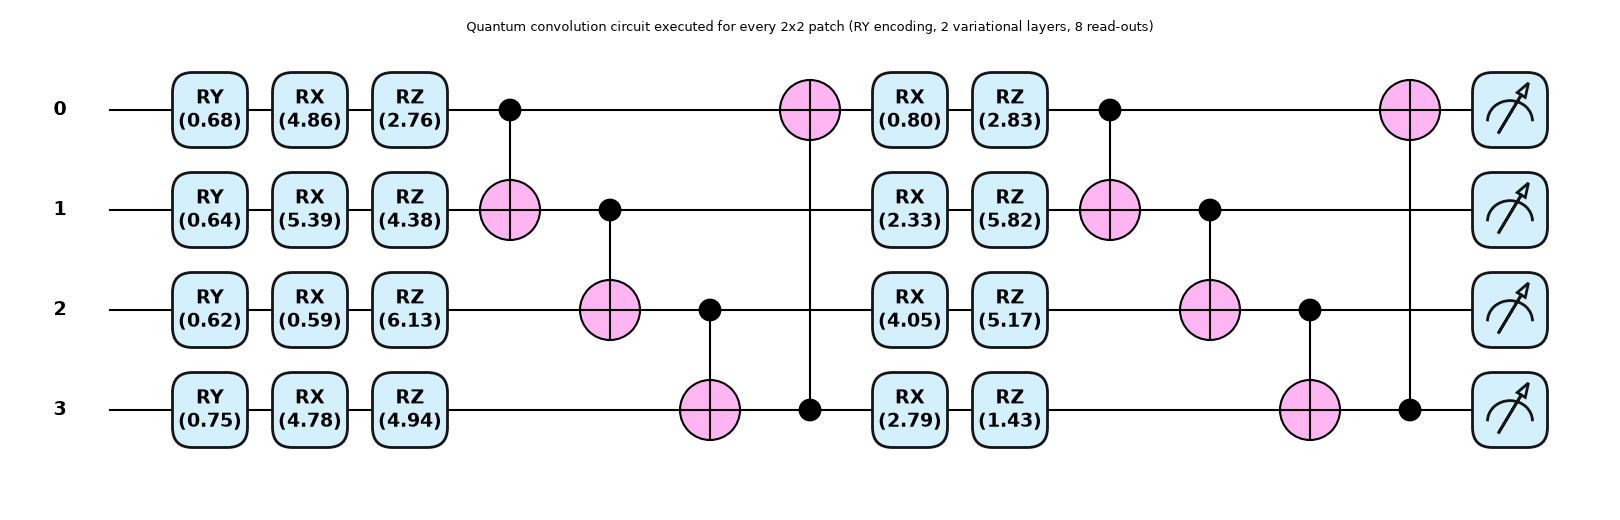

Quanvolution circuit: 4 qubits | depth 13 | 28 gates | 16 circuit angles (fixed, not trained) | 4 input angles per patch | 8 read-outs (depth=8 channels)


In [8]:
Q_N = Q_FILTER * Q_FILTER                                     # 4 qubits for a 2x2 patch
q_rng = np.random.default_rng(SEED)
QTHETA = q_rng.uniform(0, 2 * np.pi, size=(Q_LAYERS, Q_N, 2))   # CHOICE: fixed random angles [layer, qubit, (RX, RZ)]
RING = [(j, (j + 1) % Q_N) for j in range(Q_N)]
dev_q = qml.device("default.qubit", wires=Q_N)

@qml.qnode(dev_q)
def quanv_qnode(patch, theta):
    """patch: (..., 4) pixel values in [0, 1] (a leading batch axis is broadcast); returns 8 expectation values."""
    for j in range(Q_N):
        qml.RY(np.pi * patch[..., j], wires=j)                  # encoding
    for l in range(Q_LAYERS):                                   # variational layers with entanglement
        for j in range(Q_N):
            qml.RX(theta[l, j, 0], wires=j); qml.RZ(theta[l, j, 1], wires=j)
        for a, b in RING:
            qml.CNOT(wires=[a, b])
    return [qml.expval(qml.PauliZ(j)) for j in range(Q_N)] + [qml.expval(qml.PauliZ(a) @ qml.PauliZ(b)) for a, b in RING]

def circuit_stats(qnode, *args):
    sp = qml.specs(qnode)(*args)
    res = sp["resources"] if isinstance(sp, dict) else sp.resources
    get = lambda o, k: (o[k] if isinstance(o, dict) else getattr(o, k))
    return dict(qubits=get(res, "num_allocs"), depth=get(res, "depth"), gates=get(res, "num_gates"))

example_patch = (X25[0, :Q_FILTER, :Q_FILTER].reshape(-1) / 255.0)       # a real 2x2 patch of the first picture
fig, ax = qml.draw_mpl(quanv_qnode, decimals=2, style="pennylane")(example_patch, QTHETA)
fig.suptitle("Quantum convolution circuit executed for every 2x2 patch (RY encoding, 2 variational layers, 8 read-outs)", fontsize=9)
plt.show()
st = circuit_stats(quanv_qnode, example_patch, QTHETA)
print(f"Quanvolution circuit: {st['qubits']} qubits | depth {st['depth']} | {st['gates']} gates | "
      f"{QTHETA.size} circuit angles (fixed, not trained) | 4 input angles per patch | 8 read-outs (depth=8 channels)")

In [9]:
# Equivalence check: the same circuit written independently in Qiskit must give the same 8 numbers
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp

def quanv_qiskit(patch, theta):
    qc = QuantumCircuit(Q_N)
    for j in range(Q_N): qc.ry(float(np.pi * patch[j]), j)
    for l in range(Q_LAYERS):
        for j in range(Q_N):
            qc.rx(float(theta[l, j, 0]), j); qc.rz(float(theta[l, j, 1]), j)
        for a, b in RING: qc.cx(a, b)
    sv = Statevector(qc)
    def zz(idx):
        label = ["I"] * Q_N
        for i in idx: label[Q_N - 1 - i] = "Z"                    # Qiskit labels are little-endian
        return SparsePauliOp("".join(label))
    return np.array([sv.expectation_value(zz([j])).real for j in range(Q_N)] + [sv.expectation_value(zz([a, b])).real for a, b in RING])

test_patches = np.random.default_rng(1).uniform(0, 1, size=(25, Q_N))
pl_out = np.stack(quanv_qnode(test_patches, QTHETA), axis=-1)                        # PennyLane, broadcast over the 25 patches
qk_out = np.stack([quanv_qiskit(p, QTHETA) for p in test_patches])                   # Qiskit, one patch at a time
assert np.allclose(pl_out, qk_out, atol=1e-9), np.abs(pl_out - qk_out).max()
print("PennyLane == Qiskit for the quantum convolution circuit on 25 random patches (max difference %.1e)" % np.abs(pl_out - qk_out).max())

def quanvolve(imgs01, chunk=40_000):
    """imgs01: (N, H, W) floats in [0, 1] -> (N, 8, H', W') quantum feature maps (patch Q_FILTER, stride Q_STRIDE), executed on the circuit above."""
    N, H, W = imgs01.shape
    oh, ow = (H - Q_FILTER) // Q_STRIDE + 1, (W - Q_FILTER) // Q_STRIDE + 1
    patches = np.stack([imgs01[:, i * Q_STRIDE:i * Q_STRIDE + Q_FILTER, j * Q_STRIDE:j * Q_STRIDE + Q_FILTER].reshape(N, -1)
                        for i in range(oh) for j in range(ow)], axis=1).reshape(-1, Q_N)         # (N*oh*ow, 4)
    out = np.concatenate([np.stack(quanv_qnode(patches[s:s + chunk], QTHETA), axis=-1) for s in range(0, len(patches), chunk)])   # (P, 8)
    return out.reshape(N, oh, ow, 8).transpose(0, 3, 1, 2).astype(np.float32)

t0 = time.time()
XQ = quanvolve(X25.astype(np.float64) / 255.0)                    # fixed circuit -> no fitting -> no leakage; run once for all pictures
T_QUANV = time.time() - t0
print(f"quantum feature maps {XQ.shape} for {len(y)} pictures in {T_QUANV:.1f} s ({len(y) * XQ.shape[2] * XQ.shape[3]:,} circuit evaluations)")

PennyLane == Qiskit for the quantum convolution circuit on 25 random patches (max difference 3.9e-16)


quantum feature maps (840, 8, 12, 12) for 840 pictures in 9.0 s (120,960 circuit evaluations)


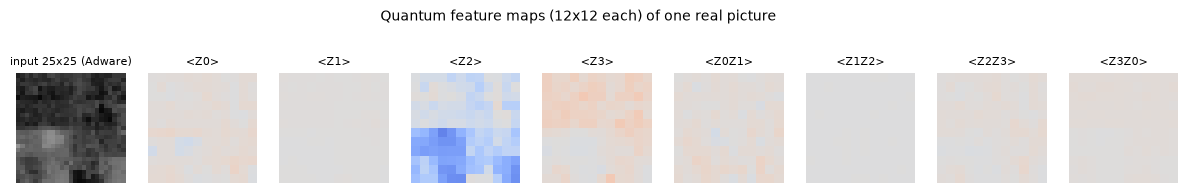

In [10]:
# What does the quantum layer produce? One picture, its 8 quantum channels (cf. the activation maps of a convolution)
k = np.where(y == 1)[0][0]
fig, axes = plt.subplots(1, 9, figsize=(15, 2.1))
axes[0].imshow(X25[k], cmap="gray", vmin=0, vmax=255); axes[0].set_title(f"input 25x25 ({NAMES[1]})", fontsize=8)
for c in range(8):
    axes[c + 1].imshow(XQ[k, c], cmap="coolwarm", vmin=-1, vmax=1); axes[c + 1].set_title(("<Z%d>" % c) if c < 4 else ("<Z%dZ%d>" % RING[c - 4]), fontsize=8)
for a in axes: a.axis("off")
plt.suptitle("Quantum feature maps (12x12 each) of one real picture", fontsize=10, y=1.06); plt.show()

### b) The fully quantum QNN (Farhi and Neven)

The paper's Listing 3 is `PQC(model_circuit, model_readout)` followed by `Dense(7, softmax)`, on a **4x4** picture. We follow the TensorFlow Quantum tutorial that the listing comes from (`# CHOICE`, the circuit is not printed in the paper):

* the 4x4 picture becomes a **16-bit string** (pixel above the training median -> 1) and is written onto 16 data qubits as a computational-basis state (`RX(pi * bit)` equals `X` up to a global phase);
* one extra **read-out qubit** is prepared in `|->` (`X` then `H`);
* one layer of `XX` gates, each between a data qubit and the read-out qubit, then one layer of `ZZ` gates, each with its own trainable angle (32 angles in total, initialised uniformly in 0 to 2pi);
* a final `H` on the read-out qubit and a measurement of `<Z>`: **one number** in [-1, 1];
* `Dense(1 -> 7)` with softmax turns that single number into class probabilities.

All 17 qubits are simulated exactly. To train quickly, the notebook uses the **closed form** of this circuit: because the read-out starts in `|->` (an eigenstate of `X`), the `XX` layer acts on every data qubit as a single-qubit rotation and the read-out value factorises,
`<Z> = - Re  prod_i [ cos(phi'_i) + i sin(phi'_i) (1 - 2 b_i) cos(phi_i) ]`, where `b_i` is bit `i`, `phi_i` the `XX` angle and `phi'_i` the `ZZ` angle of qubit `i`. The cell below asserts that this formula, the PennyLane circuit and an independent Qiskit circuit give the same read-out.

QNN simulator: lightning.qubit


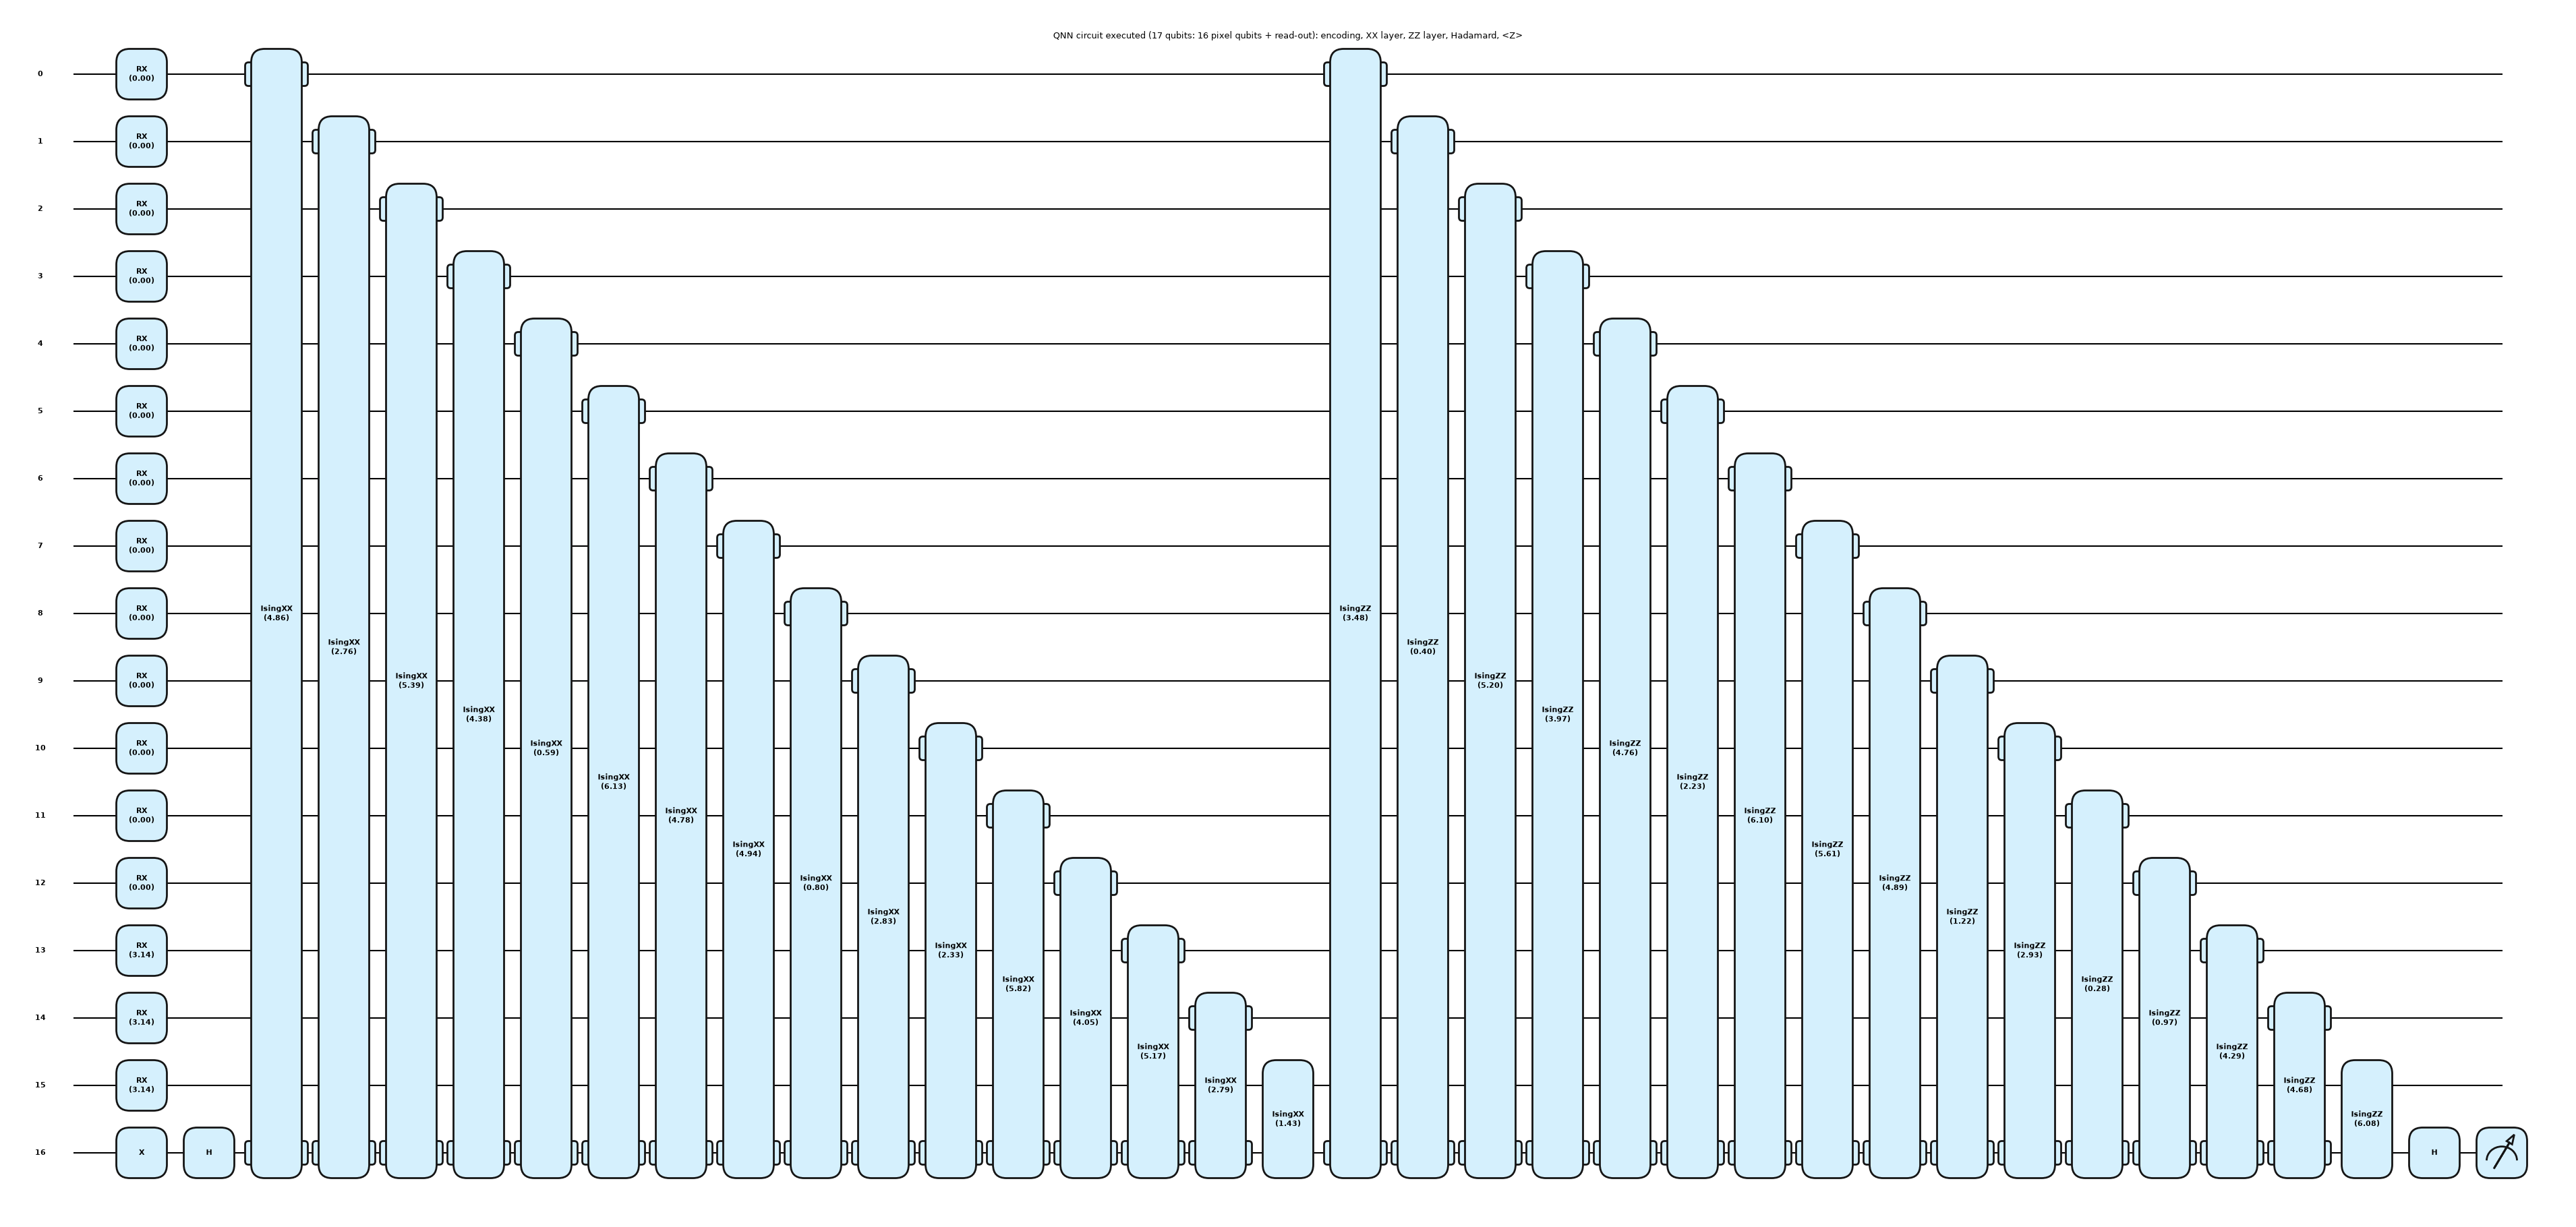

QNN circuit: 17 qubits | depth 35 | 51 gates | 32 trainable circuit angles (+ 14 parameters of the classical Dense(1->7) head)


In [11]:
N_DATA = S_QNN * S_QNN                                         # 16 data qubits (one per pixel) + 1 read-out qubit
RO = N_DATA
try:
    dev_n = qml.device("lightning.qubit", wires=N_DATA + 1)    # exact state-vector simulator (fast C++ back end)
except Exception:
    dev_n = qml.device("default.qubit", wires=N_DATA + 1)
print("QNN simulator:", dev_n.name)

@qml.qnode(dev_n)
def qnn_qnode(bits, w):
    """bits: 16 values in {0, 1}; w: (2, 16) angles [XX layer, ZZ layer]; returns <Z> of the read-out qubit."""
    for i in range(N_DATA):
        qml.RX(np.pi * bits[i], wires=i)                       # basis encoding (X up to a global phase)
    qml.PauliX(wires=RO); qml.Hadamard(wires=RO)               # read-out qubit in |->
    for i in range(N_DATA):
        qml.IsingXX(w[0, i], wires=[i, RO])                    # XX layer: every data qubit acts on the read-out qubit
    for i in range(N_DATA):
        qml.IsingZZ(w[1, i], wires=[i, RO])                    # ZZ layer
    qml.Hadamard(wires=RO)
    return qml.expval(qml.PauliZ(RO))

def qnn_readout(bits, w):
    """Closed form of qnn_qnode for a batch: bits (B, 16) in {0, 1}, w (2, 16) -> (B,) read-out values. Works on numpy-free torch tensors."""
    re = torch.ones(bits.shape[0], dtype=w.dtype); im = torch.zeros_like(re)
    for i in range(N_DATA):
        c = torch.cos(w[1, i]); s = torch.sin(w[1, i]) * (1 - 2 * bits[:, i]) * torch.cos(w[0, i])
        re, im = re * c - im * s, re * s + im * c
    return -re

def qnn_qiskit(bits, w):
    qc = QuantumCircuit(N_DATA + 1)
    for i in range(N_DATA):
        if bits[i]: qc.x(i)
    qc.x(RO); qc.h(RO)
    for i in range(N_DATA): qc.rxx(float(w[0, i]), i, RO)
    for i in range(N_DATA): qc.rzz(float(w[1, i]), i, RO)
    qc.h(RO)
    return Statevector(qc).expectation_value(SparsePauliOp("Z" + "I" * N_DATA)).real

W_demo = np.random.default_rng(SEED).uniform(0, 2 * np.pi, size=(2, N_DATA))        # the initial angles of the QNN (same draw as in training)
bits_demo = B_tr[0]                                                                  # a real training picture as 16 bits
fig, ax = qml.draw_mpl(qnn_qnode, decimals=2, style="pennylane", fontsize=8)(bits_demo, W_demo)
fig.suptitle("QNN circuit executed (17 qubits: 16 pixel qubits + read-out): encoding, XX layer, ZZ layer, Hadamard, <Z>", fontsize=9)
plt.show()
st = circuit_stats(qnn_qnode, bits_demo, W_demo)
print(f"QNN circuit: {st['qubits']} qubits | depth {st['depth']} | {st['gates']} gates | {W_demo.size} trainable circuit angles "
      f"(+ {1 * 7 + 7} parameters of the classical Dense(1->7) head)")

In [12]:
# Equivalence: PennyLane circuit == closed form (used for training) == independent Qiskit circuit
eq_rng = np.random.default_rng(3)
maxdiff = 0.0
for _ in range(12):
    b = eq_rng.integers(0, 2, size=N_DATA); w = eq_rng.uniform(0, 2 * np.pi, size=(2, N_DATA))
    v_pl = float(qnn_qnode(b.astype(float), w))
    v_cf = float(qnn_readout(torch.from_numpy(b[None].astype(np.float64)), torch.from_numpy(w))[0])
    v_qk = float(qnn_qiskit(b, w))
    maxdiff = max(maxdiff, abs(v_pl - v_cf), abs(v_pl - v_qk))
    assert abs(v_pl - v_cf) < 1e-8 and abs(v_pl - v_qk) < 1e-8, (v_pl, v_cf, v_qk)
print("PennyLane circuit == closed form == Qiskit circuit for the QNN on 12 random (picture, angle) pairs (max difference %.1e)" % maxdiff)

PennyLane circuit == closed form == Qiskit circuit for the QNN on 12 random (picture, angle) pairs (max difference 6.1e-15)


## 4. The classical networks of the paper and the ImageNet baselines

The Standard-CNN is printed in Listing 1 and copied layer by layer. AlexNet is only named, so we use a five-convolution AlexNet layout at half width (`# CHOICE`, it keeps the CPU cost reasonable).
VGG16, VGG19, MobileNet and EfficientNet are used as the paper describes for VGG16: **the convolutional part keeps its ImageNet weights and only the dense head is trained**. The frozen part never changes, so its output is computed once for every picture
(Keras Applications weights, 110x110 grey picture replicated to three channels). The head is `Dense(256) -> Dropout(0.5) -> Dense(7)` on the features standardised with training statistics (`# CHOICE`).
The four small weight files are downloaded into `DATA_DIR/keras_home` and every file above 50 MB is deleted again after the features are computed.

In [13]:
import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(N_THREADS); tf.config.threading.set_inter_op_parallelism_threads(1)
import keras
try:
    keras.config.disable_interactive_logging()
except Exception:
    pass
print("tensorflow", tf.__version__, "| keras", keras.__version__)

def to_rgb255(arr_u8, size=None):
    """(N, H, W) uint8 grey -> (N, S, S, 3) float32 in 0..255 (grey replicated to 3 channels; optional bilinear resize)."""
    x = torch.from_numpy(arr_u8.astype(np.float32))[:, None]
    if size is not None and size != x.shape[-1]:
        x = F.interpolate(x, size=(size, size), mode="bilinear", align_corners=False)
    return x.repeat(1, 3, 1, 1).permute(0, 2, 3, 1).numpy()

KA = keras.applications
PRETRAINED = {   # name: (constructor, preprocessing, source pictures, input size, pooling)
    "VGG16":                (KA.VGG16,          KA.vgg16.preprocess_input, X110, 110, None),
    "MobileNet":            (KA.MobileNet,      lambda x: x / 127.5 - 1.0, X110, 110, "avg"),
    "VGG19":                (KA.VGG19,          KA.vgg19.preprocess_input, X110, 110, None),
    "EfficientNet (110x3)": (KA.EfficientNetB0, lambda x: x,               X110, 110, "avg"),   # Keras EfficientNet rescales inside
    "EfficientNet (25x3)":  (KA.EfficientNetB0, lambda x: x,               X25,  32,  "avg"),   # CHOICE: Keras needs >= 32 px, 25 -> 32 by bilinear resize
}
FEATS, T_FEAT = {}, {}
for name, (ctor, prep, src, size, pool) in PRETRAINED.items():
    t0 = time.time()
    base = ctor(include_top=False, weights="imagenet", input_shape=(size, size, 3), pooling=pool)
    out = []
    for s in range(0, len(src), 32):
        out.append(base.predict(prep(to_rgb255(src[s:s + 32], size)), verbose=0).reshape(min(32, len(src) - s), -1))
    FEATS[name] = np.concatenate(out).astype(np.float32); T_FEAT[name] = time.time() - t0
    del base
    print(f"{name:22s} frozen ImageNet features {FEATS[name].shape} in {T_FEAT[name]:.0f} s")
# keep the cache small: delete every weight file above 50 MB
for p in glob.glob(os.path.join(os.environ["KERAS_HOME"], "**", "*"), recursive=True):
    if os.path.isfile(p) and os.path.getsize(p) > 50e6:
        os.remove(p); print("deleted", os.path.basename(p))
print("remaining cache in DATA_DIR: %.0f MB" % (sum(os.path.getsize(p) for p in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True) if os.path.isfile(p)) / 1e6))

tensorflow 2.21.0 | keras 3.15.1


VGG16                  frozen ImageNet features (840, 4608) in 703 s


MobileNet              frozen ImageNet features (840, 1024) in 103 s


VGG19                  frozen ImageNet features (840, 4608) in 1702 s


EfficientNet (110x3)   frozen ImageNet features (840, 1280) in 434 s


EfficientNet (25x3)    frozen ImageNet features (840, 1280) in 90 s
deleted vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5
deleted vgg19_weights_tf_dim_ordering_tf_kernels_notop.h5
remaining cache in DATA_DIR: 43 MB


In [14]:
class AlexNetSmall(nn.Module):               # CHOICE: AlexNet layout (5 conv, 3 pool, 3 FC) at half width for 110x110x1 input
    def __init__(s, n):
        super().__init__()
        s.f = nn.Sequential(nn.Conv2d(1, 48, 11, stride=4), nn.ReLU(), nn.MaxPool2d(3, 2),
                            nn.Conv2d(48, 128, 5, padding=2), nn.ReLU(), nn.MaxPool2d(3, 2),
                            nn.Conv2d(128, 192, 3, padding=1), nn.ReLU(), nn.Conv2d(192, 192, 3, padding=1), nn.ReLU(),
                            nn.Conv2d(192, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(3, 2), nn.Flatten())
        s.c = nn.Sequential(nn.Dropout(0.5), nn.Linear(128 * 2 * 2, 512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, n))
    def forward(s, x): return s.c(s.f(x))

class StandardCNN(nn.Module):                # Listing 1 of the paper, layer by layer (softmax lives inside the cross-entropy loss)
    def __init__(s, n, size):
        super().__init__()
        s.pre = nn.Sequential(nn.Conv2d(1, 30, 3), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(30, 15, 3), nn.ReLU())     # up to the last convolution (Grad-CAM layer)
        with torch.no_grad(): d = s.pre[:-1](torch.zeros(1, 1, size, size)).shape            # conv2 output size before pooling
        side = d[-1] // 2                                                                       # after the second MaxPool2d(2)
        s.post = nn.Sequential(nn.MaxPool2d(2), nn.Dropout(0.25), nn.Flatten(), nn.Linear(15 * side * side, 128), nn.ReLU(), nn.Dropout(0.5),
                               nn.Linear(128, 50), nn.ReLU(), nn.Linear(50, n))
    def forward(s, x): return s.post(s.pre(x))

class HybridHead(nn.Module):                 # layers 2-5 of Listing 2 on the quantum feature maps: ReLU, Conv2D(16, 2x2, relu), Flatten, Dense(32, relu), Dense(n)
    def __init__(s, n, in_ch=8, in_size=12):
        super().__init__()
        s.pre = nn.Sequential(nn.ReLU(), nn.Conv2d(in_ch, 16, 2), nn.ReLU())                 # Grad-CAM layer = output of this block (16 x 11 x 11)
        s.post = nn.Sequential(nn.Flatten(), nn.Linear(16 * (in_size - 1) ** 2, 32), nn.ReLU(), nn.Linear(32, n))
    def forward(s, x): return s.post(s.pre(x))

class ClassicalFront(nn.Module):             # classical twin of the Hybrid-QCNN: a 2x2 stride-2 convolution (8 filters) in place of the quantum layer
    def __init__(s, n, trainable=True):
        super().__init__()
        s.conv = nn.Conv2d(1, 8, Q_FILTER, stride=Q_STRIDE)
        if not trainable:
            for p in s.conv.parameters(): p.requires_grad_(False)
        s.head = HybridHead(n)
    def forward(s, x): return s.head(s.conv(x[:, :, :24, :24]))

class PretrainedHead(nn.Module):             # trained dense head on frozen ImageNet features
    def __init__(s, d, n):
        super().__init__(); s.net = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, n))
    def forward(s, x): return s.net(x)

class QNNClassifier(nn.Module):              # Listing 3: PQC (QNN circuit, one read-out number) -> Dense(n, softmax)
    def __init__(s, n, seed):
        super().__init__()
        s.w = nn.Parameter(torch.from_numpy(np.random.default_rng(seed).uniform(0, 2 * np.pi, size=(2, N_DATA))).float())   # TFQ default: uniform in 0..2pi
        s.fc = nn.Linear(1, n)
    def readout(s, bits): return qnn_readout(bits, s.w)
    def forward(s, bits): return s.fc(s.readout(bits)[:, None])

class ScalarBottleneckTwin(nn.Module):       # classical twin of the QNN: 16 bits -> ONE number (tanh) -> Dense(n); same bottleneck, no quantum circuit
    def __init__(s, n):
        super().__init__(); s.net = nn.Sequential(nn.Linear(N_DATA, 1), nn.Tanh(), nn.Linear(1, n))
    def forward(s, x): return s.net(x)

for nm, m, shp in [("AlexNet (half width)", AlexNetSmall(N_CLASSES), (1, 1, 110, 110)), ("Standard-CNN 110", StandardCNN(N_CLASSES, 110), (1, 1, 110, 110)),
                   ("Standard-CNN 25", StandardCNN(N_CLASSES, 25), (1, 1, 25, 25)), ("Hybrid head", HybridHead(N_CLASSES), (1, 8, 12, 12)),
                   ("Classical front twin", ClassicalFront(N_CLASSES), (1, 1, 25, 25)), ("QNN (circuit + Dense)", QNNClassifier(N_CLASSES, SEED), (1, N_DATA)),
                   ("Scalar-bottleneck twin", ScalarBottleneckTwin(N_CLASSES), (1, N_DATA))]:
    print(f"{nm:24s} trainable parameters: {sum(p.numel() for p in m.parameters() if p.requires_grad):>9,}   output {tuple(m(torch.zeros(shp)).shape)}")

AlexNet (half width)     trainable parameters: 1,463,143   output (1, 7)
Standard-CNN 110         trainable parameters: 1,309,220   output (1, 7)
Standard-CNN 25          trainable parameters:    42,020   output (1, 7)
Hybrid head              trainable parameters:    62,743   output (1, 7)
Classical front twin     trainable parameters:    62,783   output (1, 7)
QNN (circuit + Dense)    trainable parameters:        46   output (1, 7)
Scalar-bottleneck twin   trainable parameters:        31   output (1, 7)


## 5. Training and metrics

For every split the notebook trains all models with the batch size, number of epochs and learning rate of the paper's Table 1 and evaluates the **final** weights on the held-out test pictures (no early stopping, no model selection on the test set).
The validation split is used only to draw learning curves. Every transform that learns something from data (the median threshold of the QNN, the standardisation of the ImageNet features) is fitted on the training split only.

**Metrics.** The paper's Table 2 reports loss, accuracy, precision, recall, F-measure and AUC. Its QNN row (accuracy 0.413, recall 0.103) cannot come from arg-max averages, but it is exactly what Keras' `Precision`, `Recall` and `AUC` metrics give for softmax outputs:
a class counts as "predicted" only if its probability exceeds 0.5, and the one-vs-rest counts are pooled (micro average). We use the same definitions (`# CHOICE`) and also report the arg-max macro-F1 for comparison.
Table 3 (per class) uses one-vs-rest counts from the arg-max prediction.

In [15]:
def keras_style_metrics(y_true, proba):
    """Loss, accuracy, precision, recall, F-measure and AUC with Keras semantics (threshold 0.5 on the class probability, micro-averaged one-vs-rest)."""
    onehot = np.eye(N_CLASSES)[y_true].astype(bool)
    pred = proba > 0.5
    tp = (pred & onehot).sum(); fp = (pred & ~onehot).sum(); fn = (~pred & onehot).sum()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return dict(Loss=log_loss(y_true, np.clip(proba, 1e-7, 1), labels=range(N_CLASSES)),
                Accuracy=accuracy_score(y_true, proba.argmax(1)), Precision=prec, Recall=rec,
                F1=(2 * prec * rec / (prec + rec)) if prec + rec > 0 else 0.0,
                AUC=roc_auc_score(onehot.ravel(), proba.ravel()),
                F1_macro=f1_score(y_true, proba.argmax(1), average="macro", zero_division=0))

def train_torch(model, data, epochs, batch, lr, seed):
    """Adam + cross-entropy. data = (Xtr, ytr, Xva, yva, Xte, yte) as numpy arrays. Returns test probabilities, per-epoch curve and wall-clock time."""
    Xtr, ytr, Xva, yva, Xte, yte = data
    torch.manual_seed(seed)
    Xtr_t, ytr_t = torch.from_numpy(Xtr), torch.from_numpy(ytr).long()
    Xva_t, Xte_t = torch.from_numpy(Xva), torch.from_numpy(Xte)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    g = torch.Generator().manual_seed(seed)
    curve = []; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr_t), generator=g); tot = 0.0
        for s in range(0, len(perm), batch):
            idx = perm[s:s + batch]
            opt.zero_grad(); loss = F.cross_entropy(model(Xtr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        model.eval()
        with torch.no_grad():
            va_acc = (model(Xva_t).argmax(1).numpy() == yva).mean()          # monitoring only, never used for selection
        curve.append((tot / len(perm), va_acc))
    dt = time.time() - t0
    model.eval()
    with torch.no_grad():
        proba = F.softmax(model(Xte_t), dim=1).numpy().astype(np.float64)
    return proba, np.array(curve), dt

img_t = lambda a: (a.astype(np.float32) / 255.0)[:, None]                     # (N, 1, S, S) in [0, 1]: fixed rescaling, not fitted
MODEL_ORDER = ["AlexNet", "Standard-CNN (110x1)", "Standard-CNN (25x1)", "VGG16", "MobileNet", "VGG19", "EfficientNet (110x3)", "EfficientNet (25x3)", "Hybrid-QCNN", "QNN"]
CONTROLS = ["Twin of Hybrid: trainable 2x2 conv", "Twin of Hybrid: frozen random 2x2 conv", "Twin of QNN: scalar bottleneck (16 bits -> 1 number)"]
BASELINES = ["RandomForest (110x110 px)", "RandomForest (25x25 px)", "RandomForest (4x4 bits)", "SVC-rbf (25x25 px)"]

## 6. Run: several random splits

For every seed the notebook draws a stratified split (the same split for every model, so all models see identical training and test pictures), trains the ten model rows of Table 1, the three classical twins (whose learning rate, 0.001 or 0.01, is chosen on the validation split) and the shallow baselines, and evaluates them on the test pictures.
Learned thresholds and scalers are fitted on the training part of that split only.

In [16]:
rows, curves, probas, ytests, SPLITS, MODELS0 = [], {}, {}, {}, {}, {}
print("pictures:", len(y), "| epochs:", {k: v["epochs"] for k, v in TRAIN_CFG.items()})
T_RUN0 = time.time()
for s in range(N_SEEDS):
    seed = SEED + s
    itr, iva, ite = make_split(seed); SPLITS[seed] = (itr, iva, ite)
    ytr, yva, yte = y[itr], y[iva], y[ite]; ytests[seed] = yte
    D = lambda arr: (arr[itr], ytr, arr[iva], yva, arr[ite], yte)
    img110, img25 = img_t(X110), img_t(X25)
    thr = np.median(X4[itr])                                                   # CHOICE: QNN bit threshold = training median pixel
    bits = (X4.reshape(len(y), -1) > thr).astype(np.float32)
    def std_feats(name):                                                       # standardise the frozen ImageNet features with TRAINING statistics
        f = FEATS[name]; mu, sd = f[itr].mean(0), f[itr].std(0) + 1e-6
        return ((f - mu) / sd).astype(np.float32)
    builders = {
        "AlexNet":              lambda: (AlexNetSmall(N_CLASSES), D(img110), 0.0),
        "Standard-CNN (110x1)": lambda: (StandardCNN(N_CLASSES, 110), D(img110), 0.0),
        "Standard-CNN (25x1)":  lambda: (StandardCNN(N_CLASSES, 25), D(img25), 0.0),
        "Hybrid-QCNN":          lambda: (HybridHead(N_CLASSES), D(XQ), T_QUANV),
        "QNN":                  lambda: (QNNClassifier(N_CLASSES, seed), D(bits), 0.0),
    }
    for nm in ["VGG16", "MobileNet", "VGG19", "EfficientNet (110x3)", "EfficientNet (25x3)"]:
        builders[nm] = (lambda nm=nm: (PretrainedHead(FEATS[nm].shape[1], N_CLASSES), D(std_feats(nm)), T_FEAT[nm]))
    controls = {
        CONTROLS[0]: ("Hybrid-QCNN", lambda: (ClassicalFront(N_CLASSES, True),  D(img25))),
        CONTROLS[1]: ("Hybrid-QCNN", lambda: (ClassicalFront(N_CLASSES, False), D(img25))),
        CONTROLS[2]: ("QNN",         lambda: (ScalarBottleneckTwin(N_CLASSES),  D(bits))),
    }
    t_seed = time.time()
    for name in MODEL_ORDER:
        torch.manual_seed(seed)
        model, data, extra_t = builders[name]()
        cfg = TRAIN_CFG[name]
        proba, curve, dt = train_torch(model, data, cfg["epochs"], cfg["batch"], cfg["lr"], seed)
        rows.append(dict(seed=seed, model=name, time_s=dt + extra_t, **keras_style_metrics(yte, proba)))
        curves[(seed, name)] = curve; probas[(seed, name)] = proba
        if s == 0 and name in ("Standard-CNN (110x1)", "Hybrid-QCNN", "QNN"): MODELS0[name] = model
        print(f"  seed {seed} {name:22s} acc {rows[-1]['Accuracy']:.3f}  F1 {rows[-1]['F1']:.3f}  ({dt:.0f} s)")
    for name, (cfg_name, build) in controls.items():
        cfg = TRAIN_CFG[cfg_name]; best = None
        for lr in (1e-3, 1e-2):                      # CHOICE: the twins' learning rate is picked on the VALIDATION split (never the test split) from the two rates used in Table 1
            torch.manual_seed(seed)
            model, data = build()
            proba, curve, dt = train_torch(model, data, cfg["epochs"], cfg["batch"], lr, seed)
            if best is None or curve[-1, 1] > best[0]: best = (curve[-1, 1], lr, proba, curve, dt)
        _, lr_sel, proba, curve, dt = best
        rows.append(dict(seed=seed, model=name, time_s=dt, **keras_style_metrics(yte, proba)))
        curves[(seed, name)] = curve; probas[(seed, name)] = proba
        print(f"  seed {seed} {name[:44]:44s} acc {rows[-1]['Accuracy']:.3f}  (lr {lr_sel:g} chosen on validation, {dt:.0f} s)")
    # shallow baselines on the identical pixels / bits
    for nm, Xall, mk in [(BASELINES[0], X110, lambda: RandomForestClassifier(300, random_state=seed, n_jobs=N_THREADS)),
                         (BASELINES[1], X25,  lambda: RandomForestClassifier(300, random_state=seed, n_jobs=N_THREADS)),
                         (BASELINES[2], bits, lambda: RandomForestClassifier(300, random_state=seed, n_jobs=N_THREADS)),
                         (BASELINES[3], X25,  lambda: SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=seed))]:
        Xf = Xall.reshape(len(y), -1).astype(np.float64)
        Xf = Xf / 255.0 if Xall.dtype == np.uint8 else Xf
        t0 = time.time(); clf = mk().fit(Xf[itr], ytr); proba = clf.predict_proba(Xf[ite]); dt = time.time() - t0
        rows.append(dict(seed=seed, model=nm, time_s=dt, **keras_style_metrics(yte, proba))); probas[(seed, nm)] = proba
    print(f"seed {seed}: train {len(itr)} / validation {len(iva)} / test {len(ite)} pictures, {time.time() - t_seed:.0f} s")
results = pd.DataFrame(rows)
T_RUN = time.time() - T_RUN0
print(f"all runs finished in {T_RUN / 60:.1f} min")

pictures: 840 | epochs: {'AlexNet': 50, 'Standard-CNN (110x1)': 50, 'Standard-CNN (25x1)': 20, 'VGG16': 25, 'MobileNet': 25, 'VGG19': 25, 'EfficientNet (110x3)': 25, 'EfficientNet (25x3)': 20, 'Hybrid-QCNN': 20, 'QNN': 10}


  seed 42 AlexNet                acc 0.220  F1 0.000  (845 s)


  seed 42 Standard-CNN (110x1)   acc 0.446  F1 0.448  (944 s)


  seed 42 Standard-CNN (25x1)    acc 0.256  F1 0.000  (15 s)


  seed 42 VGG16                  acc 0.399  F1 0.377  (29 s)


...

  seed 42 QNN                    acc 0.185  F1 0.000  (3 s)


  seed 42 Twin of Hybrid: trainable 2x2 conv           acc 0.405  (lr 0.001 chosen on validation, 6 s)


  seed 42 Twin of Hybrid: frozen random 2x2 conv       acc 0.363  (lr 0.001 chosen on validation, 4 s)


  seed 42 Twin of QNN: scalar bottleneck (16 bits -> 1 acc 0.161  (lr 0.01 chosen on validation, 0 s)


seed 42: train 537 / validation 135 / test 168 pictures, 1979 s
all runs finished in 33.0 min


In [17]:
# The QNN read-out of the trained model, taken from the executed PennyLane circuit, must agree with the closed form that was used for training
w_trained = MODELS0["QNN"].w.detach().double()
itr0, iva0, ite0 = SPLITS[SEED]
thr0 = np.median(X4[itr0]); bits0 = (X4.reshape(len(y), -1) > thr0).astype(np.float64)
check_idx = ite0[:30 if FAST_MODE else 60]
v_circuit = np.array([float(qnn_qnode(bits0[i], w_trained.numpy())) for i in check_idx])
v_closed = qnn_readout(torch.from_numpy(bits0[check_idx]), w_trained).numpy()
assert np.allclose(v_circuit, v_closed, atol=1e-6), np.abs(v_circuit - v_closed).max()
print(f"trained QNN: executed PennyLane circuit == closed form on {len(check_idx)} test pictures (max difference {np.abs(v_circuit - v_closed).max():.1e})")
print("distinct read-out values on the test pictures:", len(np.unique(np.round(v_closed, 6))), "of", len(check_idx))

trained QNN: executed PennyLane circuit == closed form on 60 test pictures (max difference 5.5e-15)
distinct read-out values on the test pictures: 53 of 60


## 7. Results: the counterpart of the paper's Table 2

Mean +- standard deviation over the random splits (one split in `FAST_MODE`, where the std is 0 by construction). Loss is the cross-entropy of the predicted probabilities; precision, recall, F-measure and AUC follow the Keras definitions explained above; `Time` is wall-clock training time on one CPU thread
(for the Hybrid-QCNN it includes the simulation of the quantum layer, for the ImageNet rows the frozen feature extraction). Chance level for seven balanced classes is accuracy 0.143.

In [18]:
metric_cols = ["Loss", "Accuracy", "Precision", "Recall", "F1", "AUC", "F1_macro", "time_s"]
agg = results.groupby("model")[metric_cols].agg(["mean", "std"]).fillna(0.0)
order = MODEL_ORDER + CONTROLS + BASELINES
table = pd.DataFrame({c: [f"{agg.loc[m, (c, 'mean')]:.3f} +- {agg.loc[m, (c, 'std')]:.3f}" for m in order] for c in metric_cols}, index=order)
table.columns = ["Loss", "Accuracy", "Precision", "Recall", "F-measure", "AUC", "macro-F1 (arg-max)", "Time [s]"]
display(table)
print("test pictures per split:", len(ytests[SEED]), "| splits:", N_SEEDS)

,Loss,Accuracy,Precision,Recall,F-measure,AUC,macro-F1 (arg-max),Time [s]
AlexNet,1.878 +- 0.000,0.220 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.627 +- 0.000,0.126 +- 0.000,845.389 +- 0.000
Standard-CNN (110x1),2.692 +- 0.000,0.446 +- 0.000,0.477 +- 0.000,0.423 +- 0.000,0.448 +- 0.000,0.780 +- 0.000,0.440 +- 0.000,944.070 +- 0.000
Standard-CNN (25x1),1.778 +- 0.000,0.256 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.685 +- 0.000,0.197 +- 0.000,14.750 +- 0.000
VGG16,5.423 +- 0.000,0.399 +- 0.000,0.407 +- 0.000,0.351 +- 0.000,0.377 +- 0.000,0.657 +- 0.000,0.398 +- 0.000,731.918 +- 0.000
MobileNet,2.862 +- 0.000,0.333 +- 0.000,0.383 +- 0.000,0.292 +- 0.000,0.331 +- 0.000,0.716 +- 0.000,0.330 +- 0.000,108.849 +- 0.000
VGG19,5.935 +- 0.000,0.357 +- 0.000,0.367 +- 0.000,0.321 +- 0.000,0.343 +- 0.000,0.639 +- 0.000,0.356 +- 0.000,1720.740 +- 0.000
EfficientNet (110x3),2.149 +- 0.000,0.417 +- 0.000,0.453 +- 0.000,0.369 +- 0.000,0.407 +- 0.000,0.772 +- 0.000,0.414 +- 0.000,437.251 +- 0.000
EfficientNet (25x3),2.221 +- 0.000,0.393 +- 0.000,0.444 +- 0.000,0.327 +- 0.000,0.377 +- 0.000,0.727 +- 0.000,0.393 +- 0.000,92.619 +- 0.000
Hybrid-QCNN,1.807 +- 0.000,0.369 +- 0.000,0.549 +- 0.000,0.232 +- 0.000,0.326 +- 0.000,0.737 +- 0.000,0.365 +- 0.000,13.332 +- 0.000
QNN,1.924 +- 0.000,0.185 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.000 +- 0.000,0.569 +- 0.000,0.112 +- 0.000,2.580 +- 0.000


test pictures per split: 168 | splits: 1


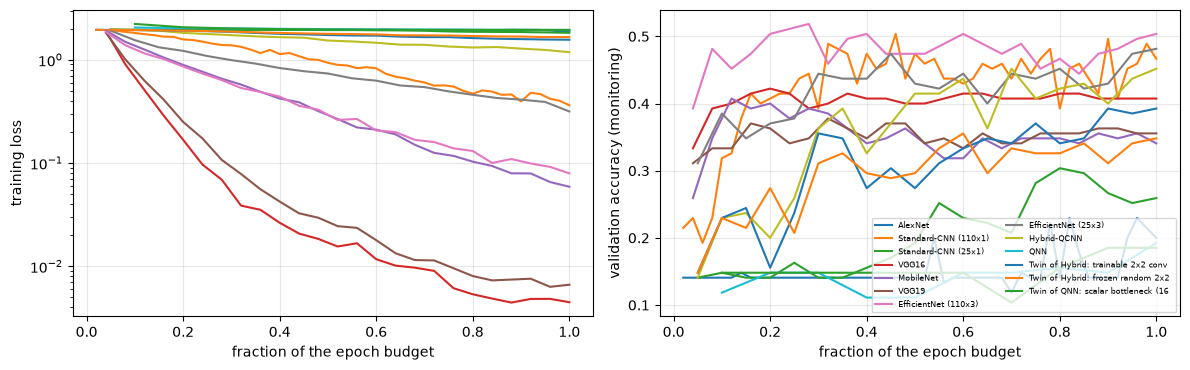

In [19]:
# Learning curves of the first split: training loss and (monitoring only) validation accuracy per epoch
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name in MODEL_ORDER + CONTROLS:
    cv = curves[(SEED, name)]
    axes[0].plot(np.arange(1, len(cv) + 1) / len(cv), cv[:, 0], label=name[:34])
    axes[1].plot(np.arange(1, len(cv) + 1) / len(cv), cv[:, 1], label=name[:34])
axes[0].set_ylabel("training loss"); axes[1].set_ylabel("validation accuracy (monitoring)")
for a in axes: a.set_xlabel("fraction of the epoch budget"); a.grid(alpha=.3)
axes[0].set_yscale("log"); axes[1].legend(fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

### Figures 6 and 7: confusion matrices of the best classical model and of the Hybrid-QCNN

Rows are the true class, columns the predicted class (first split). The paper observes that the Hybrid-QCNN's mistakes are mostly malware (Airpush, Dowgin) predicted as Trusted.

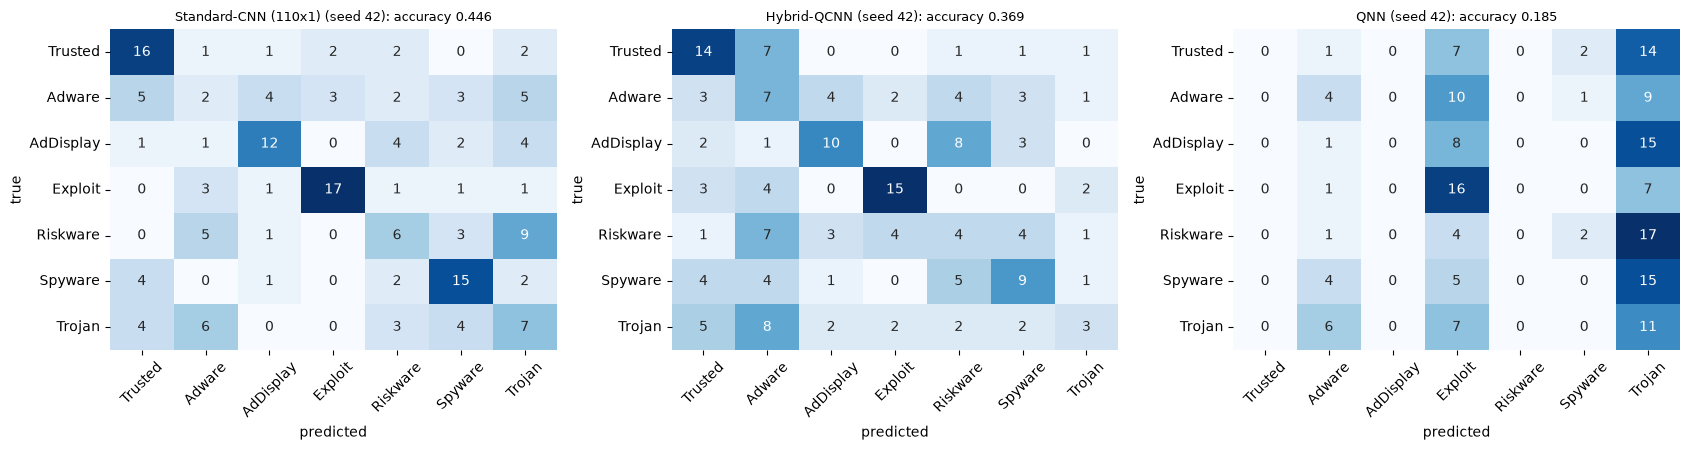

best classical model in this run: Standard-CNN (110x1)


In [20]:
import seaborn as sns
best_classical = max(["Standard-CNN (110x1)", "AlexNet", "VGG16", "MobileNet", "VGG19"], key=lambda m: agg.loc[m, ("Accuracy", "mean")])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, name in zip(axes, [best_classical, "Hybrid-QCNN", "QNN"]):
    pr = probas[(SEED, name)].argmax(1)
    cm = confusion_matrix(ytests[SEED], pr, labels=range(N_CLASSES))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=NAMES, yticklabels=NAMES)
    ax.set_title(f"{name} (seed {SEED}): accuracy {np.trace(cm) / cm.sum():.3f}", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print("best classical model in this run:", best_classical)

### Table 3: per-class accuracy, precision, recall, F-measure and AUC of the Standard-CNN and the Hybrid-QCNN (pooled over all splits)

One-vs-rest counts from the arg-max prediction, as in the paper's Table 3 (the "accuracy" of a class is the one-vs-rest accuracy).

In [21]:
def per_class_table(name):
    yt = np.concatenate([ytests[SEED + s] for s in range(N_SEEDS)]); pr = np.concatenate([probas[(SEED + s, name)] for s in range(N_SEEDS)])
    yp = pr.argmax(1); recs = {}
    for ci in range(N_CLASSES):
        tp = ((yp == ci) & (yt == ci)).sum(); fp = ((yp == ci) & (yt != ci)).sum(); fn = ((yp != ci) & (yt == ci)).sum(); tn = ((yp != ci) & (yt != ci)).sum()
        p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
        recs[NAMES[ci]] = dict(Accuracy=(tp + tn) / len(yt), Precision=p, Recall=r, F1=(2 * p * r / (p + r)) if p + r > 0 else 0.0,
                               AUC=roc_auc_score(yt == ci, pr[:, ci]))
    return pd.DataFrame(recs).T.round(3)
PC = {nm: per_class_table(nm) for nm in ["Standard-CNN (110x1)", "Hybrid-QCNN"]}
display(pd.concat(PC, axis=1))

Standard-CNN (110x1)                                Hybrid-QCNN                               
                      Accuracy Precision Recall     F1    AUC    Accuracy Precision Recall     F1    AUC
Trusted                  0.869     0.533  0.667  0.593  0.880       0.833     0.438  0.583  0.500  0.861
Adware                   0.774     0.111  0.083  0.095  0.649       0.714     0.184  0.292  0.226  0.609
AdDisplay                0.881     0.600  0.500  0.545  0.853       0.857     0.500  0.417  0.455  0.800
Exploit                  0.929     0.773  0.708  0.739  0.909       0.899     0.652  0.625  0.638  0.875
Riskware                 0.810     0.300  0.250  0.273  0.632       0.762     0.167  0.167  0.167  0.615
Spyware                  0.869     0.536  0.625  0.577  0.826       0.833     0.409  0.375  0.391  0.737
Trojan                   0.762     0.233  0.292  0.259  0.626       0.839     0.333  0.125  0.182  0.605

## 8. Grad-CAM: where does the decision come from, and can we measure it?

**Grad-CAM** (Selvaraju et al., 2017) takes the feature maps `A_k` of the last convolutional layer, weights each map by the average gradient of the predicted class score with respect to it, `alpha_k = mean(dScore / dA_k)`, and shows `ReLU(sum_k alpha_k A_k)` as a heat map over the picture.
The paper applies it to the Standard-CNN (its best model) and to the Hybrid-QCNN (the best quantum model). We do the same: the Grad-CAM layer is the second convolution of the Standard-CNN (52x52 map) and the `Conv2D(16, 2x2)` that follows the quantum layer in the Hybrid-QCNN (11x11 map).
Gradients flow only through the *classical* layers after the quantum feature maps, because the quantum layer is fixed (the paper does not say how TFQ's layer was handled); the heat map is mapped back to the picture by bilinear up-sampling. Models are those of the **first split**.

The paper only *shows* five heat maps. Showing is not testing, so below the heat maps are followed by four numerical tests of the paper's explanation claims.

In [22]:
def gradcam_maps(model, X, batch=64):
    """Grad-CAM of the predicted class for every row of X (the model's own input). Returns the raw ReLU'd maps (N, h, w) and the predicted classes."""
    model.eval(); cams, classes = [], []
    for s in range(0, len(X), batch):
        with torch.no_grad(): A = model.pre(X[s:s + batch])
        A = A.detach().requires_grad_(True)
        logits = model.post(A)
        cls = logits.argmax(1)
        logits.gather(1, cls[:, None]).sum().backward()
        w = A.grad.mean(dim=(2, 3), keepdim=True)                       # alpha_k
        cams.append(F.relu((w * A.detach()).sum(1))); classes.append(cls)
    return torch.cat(cams), torch.cat(classes)

def upsample_norm(cam, size):
    """Bilinear up-sampling to the picture size and per-picture normalisation to [0, 1] (1 = most important)."""
    c = F.interpolate(cam[:, None], size=(size, size), mode="bilinear", align_corners=False)[:, 0]
    mx = c.flatten(1).max(1)[0].clamp_min(1e-12)
    return c / mx[:, None, None]

itr0, iva0, ite0 = SPLITS[SEED]
yte0 = y[ite0]
model_std, model_hyb = MODELS0["Standard-CNN (110x1)"], MODELS0["Hybrid-QCNN"]
img110_te = torch.from_numpy(img_t(X110)[ite0]); XQ_te = torch.from_numpy(XQ[ite0])
cam_std_raw, pred_std_t = gradcam_maps(model_std, img110_te)
cam_hyb_raw, pred_hyb_t = gradcam_maps(model_hyb, XQ_te)
CAM_STD = upsample_norm(cam_std_raw, 110).numpy()                   # (N, 110, 110)
CAM_HYB = upsample_norm(cam_hyb_raw, 24).numpy()                    # (N, 24, 24): the quantum layer covers the central 24x24 of the 25x25 picture
pred_std, pred_hyb = pred_std_t.numpy(), pred_hyb_t.numpy()
assert (pred_std == probas[(SEED, "Standard-CNN (110x1)")].argmax(1)).all() and (pred_hyb == probas[(SEED, "Hybrid-QCNN")].argmax(1)).all()
print("test pictures:", len(yte0), "| Standard-CNN accuracy %.3f | Hybrid-QCNN accuracy %.3f" % ((pred_std == yte0).mean(), (pred_hyb == yte0).mean()))
print("Grad-CAM maps: Standard-CNN", tuple(cam_std_raw.shape[1:]), "-> 110x110 | Hybrid-QCNN", tuple(cam_hyb_raw.shape[1:]), "-> 24x24")

test pictures: 168 | Standard-CNN accuracy 0.446 | Hybrid-QCNN accuracy 0.369
Grad-CAM maps: Standard-CNN (52, 52) -> 110x110 | Hybrid-QCNN (11, 11) -> 24x24


### Counterpart of Figures 8 to 11: picture, activation map, overlay

Yellow/red = most important region, blue = unrelated, as in the paper. Three correctly classified pictures of different classes and up to two misclassified ones per model.

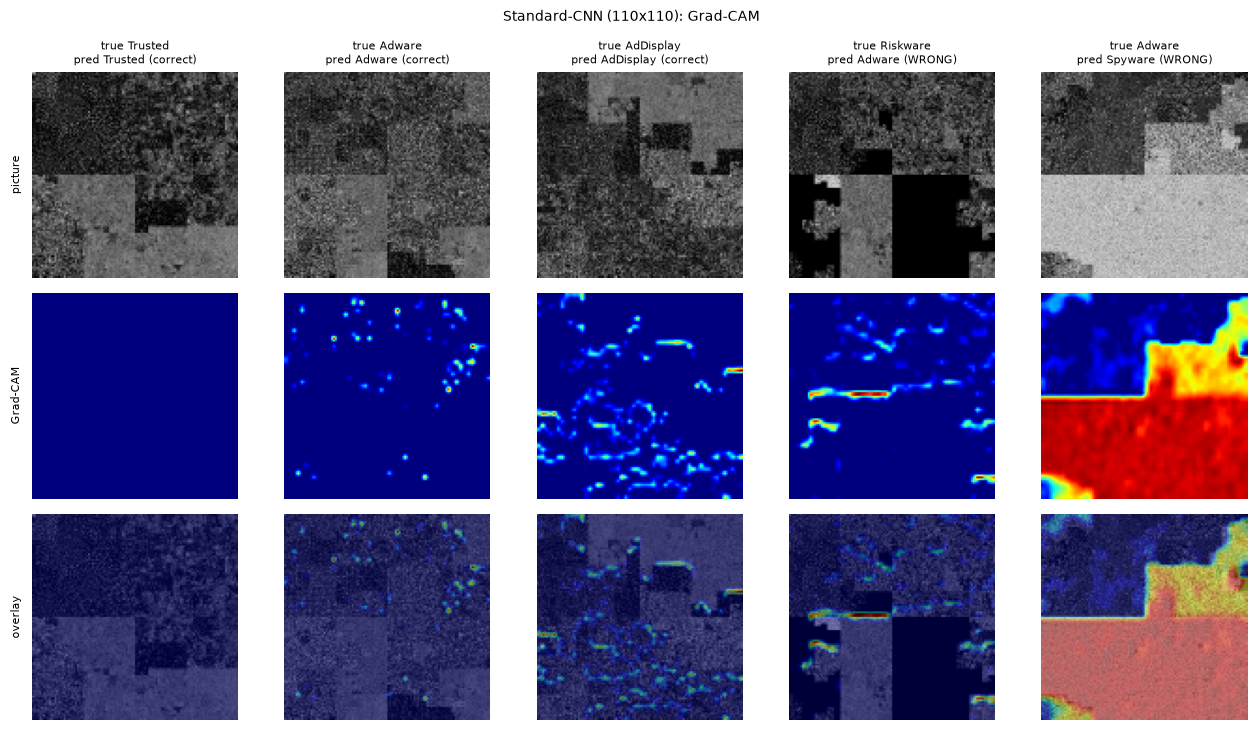

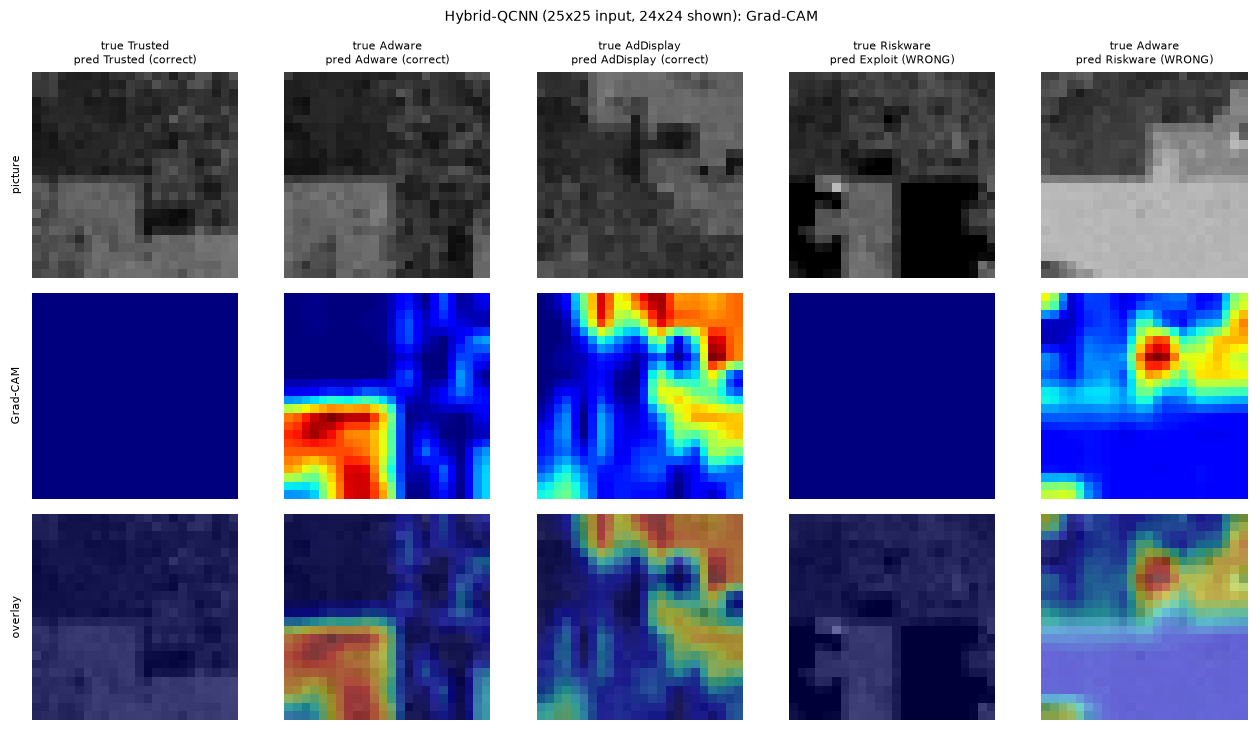

In [23]:
def show_cams(cams, imgs, pred, title, cmap_ratio):
    ok = [int(np.where((pred == yte0) & (yte0 == c))[0][0]) for c in range(N_CLASSES) if ((pred == yte0) & (yte0 == c)).any()][:3]
    bad = list(np.where(pred != yte0)[0][:2])
    sel_idx = ok + bad
    fig, axes = plt.subplots(3, len(sel_idx), figsize=(2.6 * len(sel_idx), 7.4))
    axes = np.atleast_2d(axes).reshape(3, -1)
    for col, k in enumerate(sel_idx):
        im = imgs[k]
        axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=1)
        axes[1, col].imshow(cams[k], cmap="jet", vmin=0, vmax=1)
        axes[2, col].imshow(im, cmap="gray", vmin=0, vmax=1); axes[2, col].imshow(cams[k], cmap="jet", alpha=0.45, vmin=0, vmax=1)
        tag = "correct" if pred[k] == yte0[k] else "WRONG"
        axes[0, col].set_title(f"true {NAMES[yte0[k]]}\npred {NAMES[pred[k]]} ({tag})", fontsize=8)
        for r in range(3): axes[r, col].axis("off")
    axes[0, 0].text(-0.05, 0.5, "picture", transform=axes[0, 0].transAxes, rotation=90, ha="right", va="center", fontsize=8)
    axes[1, 0].text(-0.05, 0.5, "Grad-CAM", transform=axes[1, 0].transAxes, rotation=90, ha="right", va="center", fontsize=8)
    axes[2, 0].text(-0.05, 0.5, "overlay", transform=axes[2, 0].transAxes, rotation=90, ha="right", va="center", fontsize=8)
    plt.suptitle(title, fontsize=10); plt.tight_layout(); plt.show()

imgs_std = X110[ite0].astype(np.float32) / 255.0
imgs_hyb = X25[ite0][:, :24, :24].astype(np.float32) / 255.0
show_cams(CAM_STD, imgs_std, pred_std, "Standard-CNN (110x110): Grad-CAM", None)
show_cams(CAM_HYB, imgs_hyb, pred_hyb, "Hybrid-QCNN (25x25 input, 24x24 shown): Grad-CAM", None)

### Test 1: deletion test (does the highlighted region really drive the decision?)

If the heat map marks the region the model relies on, **removing the most highlighted pixels should lower the probability of the predicted class much more than removing the same number of random pixels or the least highlighted ones.**
For up to `N_CAM_DELETION` correctly classified test pictures we replace the top 5 to 50 % of the pixels by the training-mean grey value, using four rankings: the picture's own Grad-CAM (top), its own Grad-CAM (bottom, least important first), random pixels,
and the Grad-CAM of a *different* picture (a smooth region that is not specific to this picture). For the Hybrid-QCNN the modified picture is pushed through the quantum circuit again. A paired one-sided Wilcoxon test compares the drop for "top" with the drop for "random" at 20 % deletion.

Standard-CNN: deletion test on 75 correctly classified pictures (34 s)


Hybrid-QCNN: deletion test on 62 correctly classified pictures (57 s)


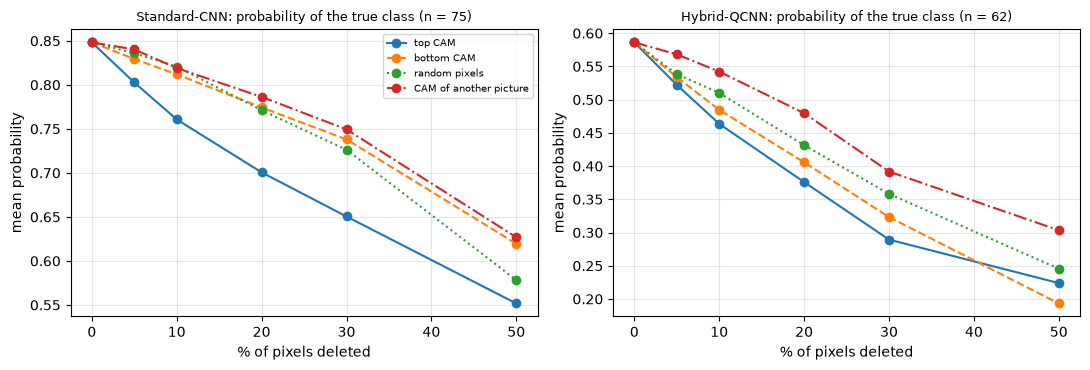

,drop_top,drop_random,drop_bottom,drop_other,p_top_vs_random,n
Standard-CNN,0.1476,0.0771,0.0739,0.0619,0.0090,75.0
Hybrid-QCNN,0.2103,0.1547,0.1806,0.1065,0.0234,62.0


In [24]:
from scipy.stats import wilcoxon, mannwhitneyu

def deletion_experiment(imgs, cams, labels, prob_fn, fill, fractions, seed):
    """imgs, cams: (M, H, W). prob_fn(imgs) -> (M, K) probabilities. Returns {method: (len(fractions), M) probability of the true class}."""
    M, H, Wd = imgs.shape
    r = np.random.default_rng(seed)
    tie = r.random(cams.shape) * 1e-9
    rank_top = np.argsort(-(cams + tie).reshape(M, -1), axis=1)                      # most important first
    rank_bot = rank_top[:, ::-1]
    rank_rnd = np.stack([r.permutation(H * Wd) for _ in range(M)])
    other = np.roll(np.arange(M), 1)                                                  # CAM of the previous picture in the list
    rank_oth = rank_top[other]
    out = {}
    for name, rank in [("top CAM", rank_top), ("bottom CAM", rank_bot), ("random pixels", rank_rnd), ("CAM of another picture", rank_oth)]:
        ps = []
        for q in fractions:
            k = int(round(q * H * Wd))
            mask = np.zeros((M, H * Wd), dtype=bool)
            if k > 0: np.put_along_axis(mask, rank[:, :k], True, axis=1)
            mod = np.where(mask.reshape(M, H, Wd), fill, imgs)
            ps.append(prob_fn(mod)[np.arange(M), labels])
        out[name] = np.array(ps)
    return out

itr0 = SPLITS[SEED][0]
fill_std = X110[itr0].mean() / 255.0; fill_hyb = X25[itr0].mean() / 255.0
def prob_std(imgs):
    with torch.no_grad(): return F.softmax(model_std(torch.from_numpy(imgs[:, None].astype(np.float32))), dim=1).numpy()
def prob_hyb(imgs24):
    q = quanvolve(imgs24.astype(np.float64))                                          # re-run the quantum circuit on the modified picture
    with torch.no_grad(): return F.softmax(model_hyb(torch.from_numpy(q)), dim=1).numpy()

DEL = {}
t0 = time.time()
for nm, imgs, cams, pred, pf, fill in [("Standard-CNN", imgs_std, CAM_STD, pred_std, prob_std, fill_std), ("Hybrid-QCNN", imgs_hyb, CAM_HYB, pred_hyb, prob_hyb, fill_hyb)]:
    ok = np.where(pred == yte0)[0][:N_CAM_DELETION]
    DEL[nm] = dict(res=deletion_experiment(imgs[ok], cams[ok], yte0[ok], pf, fill, DELETE_FRACTIONS, SEED), n=len(ok))
    print(f"{nm}: deletion test on {len(ok)} correctly classified pictures ({time.time() - t0:.0f} s)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, nm in zip(axes, DEL):
    for meth, ls in [("top CAM", "-"), ("bottom CAM", "--"), ("random pixels", ":"), ("CAM of another picture", "-.")]:
        ax.plot(np.array(DELETE_FRACTIONS) * 100, DEL[nm]["res"][meth].mean(1), ls, marker="o", label=meth)
    ax.set_title(f"{nm}: probability of the true class (n = {DEL[nm]['n']})", fontsize=9); ax.set_xlabel("% of pixels deleted"); ax.set_ylabel("mean probability"); ax.grid(alpha=.3)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

iq = DELETE_FRACTIONS.index(0.20)
DEL_STATS = {}
for nm in DEL:
    r = DEL[nm]["res"]; p0 = r["top CAM"][0]
    drop = {m: p0 - r[m][iq] for m in r}
    try:   p = wilcoxon(drop["top CAM"], drop["random pixels"], alternative="greater").pvalue
    except ValueError: p = 1.0
    DEL_STATS[nm] = dict(drop_top=drop["top CAM"].mean(), drop_random=drop["random pixels"].mean(), drop_bottom=drop["bottom CAM"].mean(),
                         drop_other=drop["CAM of another picture"].mean(), p_top_vs_random=p, n=DEL[nm]["n"])
display(pd.DataFrame(DEL_STATS).T.round(4))

### Test 2: do pictures of one class share a heat map, and pictures of different classes differ?

The paper argues that apps of one family share the payload, so Grad-CAM "should highlight the same area" for them, and a different area for other families. We measure this on the correctly classified test pictures: every heat map is reduced to a common 24x24 grid and flattened; for every pair of pictures we compute the Pearson correlation of their heat maps.
If the claim holds, pairs from the **same class** correlate more than pairs from **different classes**. We report the probability that a random same-class pair beats a random different-class pair (an AUC; 0.5 = no class information) and a permutation test with shuffled labels.
As a control we repeat the test with the raw grey pictures themselves, which tells whether the heat maps contain more class information than the picture content does.

In [25]:
def pair_stats(maps, labels, n_perm, seed):
    """maps (n, g, g); labels (n,). AUC of same-class vs different-class correlation, mean correlations and a permutation p-value for the mean difference."""
    n = len(labels); V = maps.reshape(n, -1).astype(np.float64)
    V = V - V.mean(1, keepdims=True); nrm = np.linalg.norm(V, axis=1, keepdims=True); V = V / np.maximum(nrm, 1e-12)
    C = V @ V.T; iu = np.triu_indices(n, k=1); c = C[iu]
    same = (labels[:, None] == labels[None, :])[iu]
    if same.sum() < 2 or (~same).sum() < 2: return None
    auc = mannwhitneyu(c[same], c[~same], alternative="greater").statistic / (same.sum() * (~same).sum())
    obs = c[same].mean() - c[~same].mean()
    r = np.random.default_rng(seed); cnt = 0
    for _ in range(n_perm):
        pl = r.permutation(labels); sp = (pl[:, None] == pl[None, :])[iu]
        cnt += (c[sp].mean() - c[~sp].mean()) >= obs
    return dict(AUC=auc, mean_corr_same=c[same].mean(), mean_corr_diff=c[~same].mean(), p_perm=(cnt + 1) / (n_perm + 1), n=n, pairs_same=int(same.sum()))

g24 = lambda a: F.adaptive_avg_pool2d(torch.from_numpy(a[:, None].astype(np.float32)), 24)[:, 0].numpy()
SIM = {}
for nm, cams, pred, imgs in [("Standard-CNN", CAM_STD, pred_std, imgs_std), ("Hybrid-QCNN", CAM_HYB, pred_hyb, imgs_hyb)]:
    ok = np.where(pred == yte0)[0]
    SIM[nm + " Grad-CAM"] = pair_stats(g24(cams[ok]) if cams.shape[-1] != 24 else cams[ok], yte0[ok], N_PERM, SEED)
    SIM[nm + " picture (control)"] = pair_stats(g24(imgs[ok]) if imgs.shape[-1] != 24 else imgs[ok], yte0[ok], N_PERM, SEED)
display(pd.DataFrame({k: v for k, v in SIM.items() if v is not None}).T.round(4))

,AUC,mean_corr_same,mean_corr_diff,p_perm,n,pairs_same
Standard-CNN Grad-CAM,0.5372,0.0501,0.0131,0.001,75.0,464.0
Standard-CNN picture (control),0.7016,0.4712,0.2128,0.001,75.0,464.0
Hybrid-QCNN Grad-CAM,0.6085,0.1378,0.0349,0.001,62.0,307.0
Hybrid-QCNN picture (control),0.7703,0.5051,0.1632,0.001,62.0,307.0


### Test 3: wrong predictions versus right predictions

The paper's Figures 9 and 11 suggest that a wrongly classified sample is explained by a different highlighted area than its family's usual one. We measure the correlation of each test picture's heat map with the **mean heat map of the correctly classified pictures of its true class**
(leaving the picture itself out) and ask whether wrongly classified pictures correlate less. One-sided Mann-Whitney test; at least five errors are needed.

In [26]:
def wrong_vs_right(cams, pred):
    G = g24(cams) if cams.shape[-1] != 24 else cams
    right = pred == yte0
    sims_r, sims_w = [], []
    for i in range(len(yte0)):
        pool = np.where(right & (yte0 == yte0[i]))[0]; pool = pool[pool != i]
        if len(pool) < 2: continue
        m = G[pool].mean(0).ravel(); v = G[i].ravel()
        cc = np.corrcoef(m, v)[0, 1] if m.std() > 0 and v.std() > 0 else 0.0
        (sims_r if right[i] else sims_w).append(cc)
    if len(sims_w) < 5 or len(sims_r) < 5: return dict(n_wrong=len(sims_w), n_right=len(sims_r), mean_right=np.nan, mean_wrong=np.nan, p=np.nan)
    p = mannwhitneyu(sims_r, sims_w, alternative="greater").pvalue
    return dict(n_wrong=len(sims_w), n_right=len(sims_r), mean_right=np.mean(sims_r), mean_wrong=np.mean(sims_w), p=p)
WR = {"Standard-CNN": wrong_vs_right(CAM_STD, pred_std), "Hybrid-QCNN": wrong_vs_right(CAM_HYB, pred_hyb)}
display(pd.DataFrame(WR).T.round(4))

,n_wrong,n_right,mean_right,mean_wrong,p
Standard-CNN,93.0,73.0,0.1604,0.0566,0.0184
Hybrid-QCNN,106.0,62.0,0.3400,0.2358,0.0102


### Test 4: sanity check, does the heat map depend on what the model learned?

A heat map is only an explanation if it changes when the model's knowledge is destroyed. We build the **same architecture with fresh random weights** (no training), compute its Grad-CAM for the same test pictures, and correlate it with the trained model's Grad-CAM (Adebayo et al., 2018).
A low correlation means the trained heat map reflects learned weights; a correlation near 1 would mean the picture shows the input or the architecture rather than the decision.

### Test 5: how big and where? (the Hybrid-QCNN's "small, central" areas and the Airpush "top" example)

We measure the share of the 24x24 grid in which the normalised heat map exceeds 0.5 (the "yellow" area), and the vertical centre of mass of the heat map (0 = top edge, 1 = bottom edge) per class.

In [27]:
# Test 4: model randomisation
def randomised_cam_corr(kind):
    torch.manual_seed(999)
    if kind == "std":
        m = StandardCNN(N_CLASSES, 110); cr, _ = gradcam_maps(m, img110_te); ref = cam_std_raw; size = 110
        a, b = upsample_norm(cr, 24).numpy(), upsample_norm(ref, 24).numpy()
    else:
        m = HybridHead(N_CLASSES); cr, _ = gradcam_maps(m, XQ_te); ref = cam_hyb_raw
        a, b = upsample_norm(cr, 24).numpy(), upsample_norm(ref, 24).numpy()
    cc = []
    for i in range(len(a)):
        u, v = a[i].ravel(), b[i].ravel()
        cc.append(np.corrcoef(u, v)[0, 1] if u.std() > 0 and v.std() > 0 else 0.0)
    return float(np.mean(cc)), float(np.median(cc))
RAND = {"Standard-CNN": randomised_cam_corr("std"), "Hybrid-QCNN": randomised_cam_corr("hyb")}
print("mean / median correlation between the Grad-CAM of the trained and of an untrained model of the same architecture:")
for k, v in RAND.items(): print(f"  {k:14s} mean {v[0]:+.3f} | median {v[1]:+.3f}")

# Test 5: size and position of the highlighted area
Gs, Gh = g24(CAM_STD), CAM_HYB
def area_and_centroid(G):
    area = (G >= 0.5).mean(axis=(1, 2))
    rows = np.arange(24)[None, :, None] / 23.0
    cy = (G * rows).sum(axis=(1, 2)) / np.maximum(G.sum(axis=(1, 2)), 1e-12)
    return area, cy
area_s, cy_s = area_and_centroid(Gs); area_h, cy_h = area_and_centroid(Gh)
geo = pd.DataFrame({"high-activation area (Std-CNN)": [area_s.mean()], "high-activation area (Hybrid)": [area_h.mean()]}, index=["all test pictures"])
display(geo.round(3))
cent = pd.DataFrame({"vertical centre, Std-CNN": [cy_s[yte0 == c].mean() for c in range(N_CLASSES)],
                     "vertical centre, Hybrid-QCNN": [cy_h[yte0 == c].mean() for c in range(N_CLASSES)]}, index=NAMES)
display(cent.round(3))
mw_area = mannwhitneyu(area_h, area_s, alternative="less").pvalue
print("Hybrid high-activation area smaller than the Standard-CNN's? one-sided Mann-Whitney p = %.4f" % mw_area)

mean / median correlation between the Grad-CAM of the trained and of an untrained model of the same architecture:
  Standard-CNN   mean -0.075 | median +0.000
  Hybrid-QCNN    mean -0.324 | median -0.399


,high-activation area (Std-CNN),high-activation area (Hybrid)
all test pictures,0.07,0.15


,"vertical centre, Std-CNN","vertical centre, Hybrid-QCNN"
Trusted,0.193,0.268
Adware,0.398,0.487
AdDisplay,0.455,0.517
Exploit,0.191,0.285
Riskware,0.460,0.504
Spyware,0.263,0.533
Trojan,0.482,0.395


Hybrid high-activation area smaller than the Standard-CNN's? one-sided Mann-Whitney p = 1.0000


## 9. Side by side with the paper

Verdict rule (from the project brief): an accuracy, F-measure, precision, recall or AUC within **0.02** of the paper's value is *reproduced*; otherwise *not reached* (ours is lower) or *exceeded* (ours is higher), with the gap.
Qualitative claims are checked with the rule printed in the claim. The explanation claims are *supported* or *not supported* by the numerical tests of Section 8 (a Wilcoxon / Mann-Whitney / permutation test at the 5 % level, or the threshold given in the claim);
claims that this data cannot test are *cannot be checked*. Remember that the data set differs (Section 1), so a "reproduced" verdict means that the number agrees, not that the experiment is the same; the loss column is shown but not scored because it depends on the calibration of the probabilities.

In [28]:
PAPER_T2 = {   # Table 2 of the paper (test set): Loss, Accuracy, Precision, Recall, F-measure, AUC
    "AlexNet":              dict(Loss=0.435,  Accuracy=0.912, Precision=0.920, Recall=0.908, F1=0.914, AUC=0.983),
    "Standard-CNN (110x1)": dict(Loss=0.205,  Accuracy=0.970, Precision=0.972, Recall=0.970, F1=0.971, AUC=0.993),
    "Standard-CNN (25x1)":  dict(Loss=0.260,  Accuracy=0.915, Precision=0.927, Recall=0.910, F1=0.919, AUC=0.993),
    "VGG16":                dict(Loss=0.182,  Accuracy=0.952, Precision=0.959, Recall=0.949, F1=0.954, AUC=0.993),
    "MobileNet":            dict(Loss=0.124,  Accuracy=0.966, Precision=0.969, Recall=0.963, F1=0.966, AUC=0.996),
    "VGG19":                dict(Loss=0.187,  Accuracy=0.951, Precision=0.953, Recall=0.947, F1=0.950, AUC=0.994),
    "EfficientNet (110x3)": dict(Loss=23.738, Accuracy=0.065, Precision=0.065, Recall=0.065, F1=0.065, AUC=0.455),
    "EfficientNet (25x3)":  dict(Loss=2.343,  Accuracy=0.251, Precision=0.135, Recall=0.022, F1=0.038, AUC=0.535),
    "Hybrid-QCNN":          dict(Loss=1.045,  Accuracy=0.905, Precision=0.905, Recall=0.903, F1=0.904, AUC=0.962),
    "QNN":                  dict(Loss=1.584,  Accuracy=0.413, Precision=0.623, Recall=0.103, F1=0.176, AUC=0.762),
}
PAPER_T3_F1 = {"Standard-CNN (110x1)": [0.929, 0.874, 0.995, 0.998, 0.973, 0.998, 0.905], "Hybrid-QCNN": [0.824, 0.699, 0.982, 0.994, 0.953, 0.996, 0.729]}
# order of Table 3: Airpush, Dowgin, FakeInst, Fusob, Jisut, Mecor, Trusted (our classes are categories, so only Trusted is comparable)

def verdict(ours, paper, tol=0.02):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})"

M = lambda m, c: agg.loc[m, (c, "mean")]
recs = []
for m in MODEL_ORDER:
    for c, tol in [("Accuracy", 0.02), ("F1", 0.02)]:
        recs.append(dict(claim=f"{m}: {c}", paper=PAPER_T2[m][c], notebook=round(M(m, c), 3), verdict=verdict(M(m, c), PAPER_T2[m][c], tol)))
for m in ["Standard-CNN (110x1)", "Hybrid-QCNN", "QNN"]:
    for c in ["Precision", "Recall", "AUC"]:
        recs.append(dict(claim=f"{m}: {c}", paper=PAPER_T2[m][c], notebook=round(M(m, c), 3), verdict=verdict(M(m, c), PAPER_T2[m][c], 0.02)))
# Table 3: only the class that means the same thing in both data sets (Trusted = benign) can be compared number by number
for mname in ["Standard-CNN (110x1)", "Hybrid-QCNN"]:
    pv = PAPER_T3_F1[mname][6]; ours = float(PC[mname].loc["Trusted", "F1"])
    recs.append(dict(claim=f"{mname}: F-measure of 'Trusted' (Table 3)", paper=pv, notebook=round(ours, 3), verdict=verdict(ours, pv, 0.02)))
recs.append(dict(claim="Table 3: per-family F-measures of Airpush, Dowgin, FakeInst, Fusob, Jisut, Mecor (12 numbers)", paper="0.699 to 0.998", notebook="MalVis has malware categories, not these families",
                 verdict="cannot be checked"))
n_better = int(sum(PC["Standard-CNN (110x1)"]["F1"].values >= PC["Hybrid-QCNN"]["F1"].values))
recs.append(dict(claim="Table 3 pattern: the Standard-CNN's F-measure is at least the Hybrid-QCNN's in every class (7 of 7)", paper="7 of 7", notebook=f"{n_better} of 7",
                 verdict="reproduced" if n_better == 7 else f"not reached ({n_better} of 7)"))

acc = {m: M(m, "Accuracy") for m in MODEL_ORDER}
best = max(acc, key=acc.get)
recs.append(dict(claim="The Standard-CNN (110) is the most accurate of the ten rows", paper="best (0.970)", notebook=f"best = {best} ({acc[best]:.3f}); Std-CNN {acc['Standard-CNN (110x1)']:.3f}",
                 verdict="reproduced" if best == "Standard-CNN (110x1)" else "not reached"))
recs.append(dict(claim="Hybrid-QCNN is the better of the two quantum models", paper="0.905 vs 0.413", notebook=f"{acc['Hybrid-QCNN']:.3f} vs {acc['QNN']:.3f}",
                 verdict="reproduced" if acc["Hybrid-QCNN"] > acc["QNN"] else "not reached"))
recs.append(dict(claim="The QNN does poorly (accuracy < 0.5 and recall < 0.2)", paper="0.413 / 0.103", notebook=f"{acc['QNN']:.3f} / {M('QNN', 'Recall'):.3f}",
                 verdict="reproduced" if acc["QNN"] < 0.5 and M("QNN", "Recall") < 0.2 else "not reached"))
recs.append(dict(claim="Hybrid-QCNN (25x25) is more accurate than EfficientNet (25x3)", paper="0.905 vs 0.251", notebook=f"{acc['Hybrid-QCNN']:.3f} vs {acc['EfficientNet (25x3)']:.3f}",
                 verdict="reproduced" if acc["Hybrid-QCNN"] > acc["EfficientNet (25x3)"] else "not reached"))
dgap = acc["Standard-CNN (25x1)"] - acc["Hybrid-QCNN"]
recs.append(dict(claim="At 25x25 the Standard-CNN is only slightly above the Hybrid-QCNN (paper gap +0.010; accepted: -0.01 to +0.03)", paper="+0.010", notebook=f"{dgap:+.3f}",
                 verdict="reproduced" if -0.01 <= dgap <= 0.03 else ("not reached (gap larger)" if dgap > 0.03 else "exceeded (Hybrid is ahead)")))
twin = max(M(CONTROLS[0], "Accuracy"), M(CONTROLS[1], "Accuracy"))
recs.append(dict(claim="(implied) the quantum layer helps: Hybrid-QCNN beats a classical 2x2 convolution in the same slot by more than 0.02", paper="not tested", notebook=f"Hybrid {acc['Hybrid-QCNN']:.3f} vs best twin {twin:.3f}",
                 verdict="supported" if acc["Hybrid-QCNN"] - twin > 0.02 else "not supported"))
ratio = M("Hybrid-QCNN", "time_s") / max(M("Standard-CNN (25x1)", "time_s"), 1e-9)
recs.append(dict(claim="Hybrid-QCNN training takes orders of magnitude longer (>= 20x) than the Standard-CNN at 25x25", paper="29 h 39 min vs 1 min 34 s (1135x)", notebook=f"{M('Hybrid-QCNN', 'time_s'):.0f} s vs {M('Standard-CNN (25x1)', 'time_s'):.0f} s ({ratio:.1f}x)",
                 verdict="reproduced" if ratio >= 20 else f"not reached ({ratio:.1f}x: the fixed circuit is simulated once)"))
yt_h = np.concatenate([ytests[SEED + s] for s in range(N_SEEDS)]); yp_h = np.concatenate([probas[(SEED + s, "Hybrid-QCNN")].argmax(1) for s in range(N_SEEDS)])
wrong = yt_h != yp_h
share = ((yp_h == 0) & wrong).sum() / max(wrong.sum(), 1)                  # class 0 = benign = Trusted
recs.append(dict(claim="Hybrid-QCNN errors are mostly malware predicted as Trusted (share of all errors >= 0.5)", paper="majority (Airpush 24, Dowgin 25 of the errors)", notebook=f"{share:.2f} of {int(wrong.sum())} errors",
                 verdict="reproduced" if share >= 0.5 else f"not reached (share {share:.2f})"))

# explanation claims (Section 8)
for nm in ["Standard-CNN", "Hybrid-QCNN"]:
    d = DEL_STATS[nm]
    ok = (d["p_top_vs_random"] < 0.05) and (d["drop_top"] > d["drop_random"])
    recs.append(dict(claim=f"{nm}: deleting the Grad-CAM region lowers the true-class probability more than deleting random pixels (20 %, Wilcoxon p < 0.05)", paper="asserted, not tested",
                     notebook=f"drop {d['drop_top']:.3f} vs {d['drop_random']:.3f} (bottom {d['drop_bottom']:.3f}, other {d['drop_other']:.3f}), p = {d['p_top_vs_random']:.3g}", verdict="supported" if ok else "not supported"))
for nm in ["Standard-CNN", "Hybrid-QCNN"]:
    s_ = SIM[nm + " Grad-CAM"]; c_ = SIM[nm + " picture (control)"]
    if s_ is None: recs.append(dict(claim=f"{nm}: same-class pictures share a heat map", paper="asserted, not tested", notebook="too few correct pictures", verdict="cannot be checked")); continue
    ok = (s_["p_perm"] < 0.05) and (s_["AUC"] > 0.55)
    recs.append(dict(claim=f"{nm}: same-class pictures have more similar heat maps than different-class pictures (AUC > 0.55, permutation p < 0.05)", paper="asserted, not tested",
                     notebook=f"AUC {s_['AUC']:.3f}, p = {s_['p_perm']:.3g} (raw-picture control AUC {c_['AUC']:.3f})", verdict="supported" if ok else "not supported"))
for nm in ["Standard-CNN", "Hybrid-QCNN"]:
    w_ = WR[nm]
    if np.isnan(w_["p"]): recs.append(dict(claim=f"{nm}: wrong predictions have heat maps that differ from their class's usual map", paper="Figures 9 and 11 (one example each)", notebook=f"{w_['n_wrong']} errors: too few", verdict="cannot be checked")); continue
    recs.append(dict(claim=f"{nm}: wrongly classified pictures correlate less with their class's mean heat map (Mann-Whitney p < 0.05)", paper="Figures 9 and 11 (one example each)",
                     notebook=f"right {w_['mean_right']:.3f} vs wrong {w_['mean_wrong']:.3f}, p = {w_['p']:.3g}", verdict="supported" if w_["p"] < 0.05 else "not supported"))
for nm in ["Standard-CNN", "Hybrid-QCNN"]:
    recs.append(dict(claim=f"{nm}: the heat map depends on the learned weights (correlation with an untrained model's map < 0.5)", paper="not tested", notebook=f"mean correlation {RAND[nm][0]:+.3f}", verdict="supported" if RAND[nm][0] < 0.5 else "not supported"))
recs.append(dict(claim="Hybrid-QCNN highlights smaller areas than the Standard-CNN (Mann-Whitney p < 0.05)", paper="Figure 10/11: 'really small' yellow areas", notebook=f"area {area_h.mean():.3f} vs {area_s.mean():.3f}, p = {mw_area:.3g}",
                 verdict="supported" if mw_area < 0.05 else "not supported"))
recs.append(dict(claim="For an Airpush-like (adware) sample the Standard-CNN highlights the top of the picture", paper="Figure 8 (one sample)", notebook=f"adware vertical centre {cent.loc['Adware', 'vertical centre, Std-CNN']:.2f} (0 = top)",
                 verdict="cannot be checked"))
claims = pd.DataFrame(recs)
ok_mask = claims.verdict.str.startswith(("reproduced", "supported"))
unk_mask = claims.verdict.str.startswith("cannot")
display(claims)
print(f"\nVerdict counts over {len(claims)} claims: reproduced/supported {int(ok_mask.sum())} | not reached/exceeded/not supported {int((~ok_mask & ~unk_mask).sum())} | cannot be checked {int(unk_mask.sum())}")
print("  of which numerical claims of Tables 2 and 3:", int(claims.claim.str.contains(r": (?:Accuracy|F1|Precision|Recall|AUC|F-measure)").sum()),
      "| reproduced among them:", int((ok_mask & claims.claim.str.contains(r": (?:Accuracy|F1|Precision|Recall|AUC|F-measure)")).sum()))

,claim,paper,notebook,verdict
0,AlexNet: Accuracy,0.912,0.22,not reached (-0.692)
1,AlexNet: F1,0.914,0.0,not reached (-0.914)
2,Standard-CNN (110x1): Accuracy,0.97,0.446,not reached (-0.524)
3,Standard-CNN (110x1): F1,0.971,0.448,not reached (-0.523)
4,Standard-CNN (25x1): Accuracy,0.915,0.256,not reached (-0.659)
5,Standard-CNN (25x1): F1,0.919,0.0,not reached (-0.919)
6,VGG16: Accuracy,0.952,0.399,not reached (-0.553)
7,VGG16: F1,0.954,0.377,not reached (-0.577)
8,MobileNet: Accuracy,0.966,0.333,not reached (-0.633)
9,MobileNet: F1,0.966,0.331,not reached (-0.635)



Verdict counts over 51 claims: reproduced/supported 10 | not reached/exceeded/not supported 39 | cannot be checked 2
  of which numerical claims of Tables 2 and 3: 31 | reproduced among them: 0


paper                                         notebook                                        
                        Loss Accuracy Precision Recall     F1    AUC     Loss Accuracy Precision Recall     F1    AUC
AlexNet                0.435    0.912     0.920  0.908  0.914  0.983    1.878    0.220     0.000  0.000  0.000  0.627
Standard-CNN (110x1)   0.205    0.970     0.972  0.970  0.971  0.993    2.692    0.446     0.477  0.423  0.448  0.780
Standard-CNN (25x1)    0.260    0.915     0.927  0.910  0.919  0.993    1.778    0.256     0.000  0.000  0.000  0.685
VGG16                  0.182    0.952     0.959  0.949  0.954  0.993    5.423    0.399     0.407  0.351  0.377  0.657
MobileNet              0.124    0.966     0.969  0.963  0.966  0.996    2.862    0.333     0.383  0.292  0.331  0.716
VGG19                  0.187    0.951     0.953  0.947  0.950  0.994    5.935    0.357     0.367  0.321  0.343  0.639
EfficientNet (110x3)  23.738    0.065     0.065  0.065  0.065  0.455    2.149    0.417     0.453  0.369  0.407  0.772
EfficientNet (25x3)    2.343    0.251     0.135  0.022  0.038  0.535    2.221    0.393     0.444  0.327  0.377  0.727
Hybrid-QCNN            1.045    0.905     0.905  0.903  0.904  0.962    1.807    0.369     0.549  0.232  0.326  0.737
QNN                    1.584    0.413     0.623  0.103  0.176  0.762    1.924    0.185     0.000  0.000  0.000  0.569

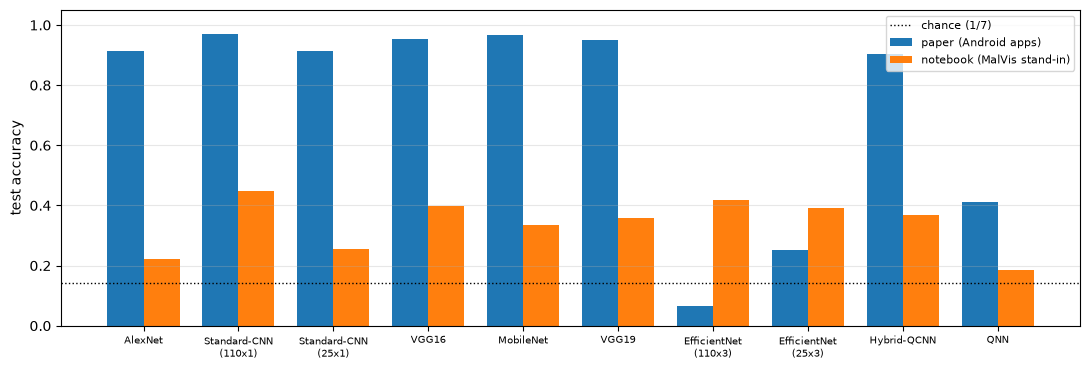

Total notebook run time: 91.5 min (FAST_MODE=False, N_PER_CLASS=120, splits=1)


In [29]:
# Table 2 side by side (paper | notebook mean) and an accuracy bar chart
side = pd.concat({"paper": pd.DataFrame(PAPER_T2).T[["Loss", "Accuracy", "Precision", "Recall", "F1", "AUC"]],
                  "notebook": pd.DataFrame({m: {c: M(m, c) for c in ["Loss", "Accuracy", "Precision", "Recall", "F1", "AUC"]} for m in MODEL_ORDER}).T}, axis=1).round(3)
display(side)
fig, ax = plt.subplots(figsize=(11, 3.8))
xs = np.arange(len(MODEL_ORDER)); w = 0.38
ax.bar(xs - w / 2, [PAPER_T2[m]["Accuracy"] for m in MODEL_ORDER], w, label="paper (Android apps)")
ax.bar(xs + w / 2, [M(m, "Accuracy") for m in MODEL_ORDER], w, yerr=[agg.loc[m, ("Accuracy", "std")] for m in MODEL_ORDER], label="notebook (MalVis stand-in)")
ax.axhline(1 / N_CLASSES, color="k", ls=":", lw=1, label="chance (1/7)")
ax.set_xticks(xs); ax.set_xticklabels([m.replace(" (", "\n(") for m in MODEL_ORDER], fontsize=7); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()
print(f"Total notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE={FAST_MODE}, N_PER_CLASS={N_PER_CLASS}, splits={N_SEEDS})")

## 10. What the controls say about the quantum parts

The twins fill the gaps in the paper's design: same head, same input, same training budget, only the first layer (Hybrid) or the one-qubit bottleneck (QNN) differs. Differences of a few accuracy points are inside the noise of a test set this small.

In [30]:
ctrl = results[results.model.isin(["Hybrid-QCNN"] + CONTROLS[:2] + ["Standard-CNN (25x1)", "QNN", CONTROLS[2]] + BASELINES)].groupby("model")[["Accuracy", "F1_macro", "AUC"]].agg(["mean", "std"]).fillna(0)
display(ctrl.round(3))

Accuracy      F1_macro         AUC     
                                                         mean  std     mean  std   mean  std
model                                                                                       
Hybrid-QCNN                                             0.369  0.0    0.365  0.0  0.737  0.0
QNN                                                     0.185  0.0    0.112  0.0  0.569  0.0
RandomForest (110x110 px)                               0.446  0.0    0.443  0.0  0.782  0.0
RandomForest (25x25 px)                                 0.458  0.0    0.440  0.0  0.812  0.0
RandomForest (4x4 bits)                                 0.405  0.0    0.400  0.0  0.741  0.0
SVC-rbf (25x25 px)                                      0.440  0.0    0.427  0.0  0.799  0.0
Standard-CNN (25x1)                                     0.256  0.0    0.197  0.0  0.685  0.0
Twin of Hybrid: frozen random 2x2 conv                  0.363  0.0    0.331  0.0  0.718  0.0
Twin of Hybrid: trainable 2x2 conv                      0.405  0.0    0.364  0.0  0.744  0.0
Twin of QNN: scalar bottleneck (16 bits -> 1 number)    0.161  0.0    0.061  0.0  0.524  0.0

## 11. Reading the paper critically

**What this run found (single split, 120 pictures per class, 168 test pictures; the numbers are those printed above).** Of 51 checked claims, 10 are reproduced or supported, 39 are not reached / exceeded / not supported and 2 cannot be checked; **none of the 31 numerical claims of the paper's Tables 2 and 3 is within 0.02**.
The best model here is the Standard-CNN (110x110) with accuracy 0.446 (paper 0.970); the Hybrid-QCNN reaches 0.369 (paper 0.905), the QNN 0.185 (paper 0.413; chance is 0.143). Because the data set is a different, harder one (Section 1), the absolute gap says nothing about the paper's own data;
the points below are about what the paper's *design* can and cannot support.

* **The ranking of architectures is mostly within noise.** With 168 test pictures the standard error of an accuracy near 0.4 is about 3.8 points, and there is one split. Standard-CNN 0.446, EfficientNet (110) 0.417, VGG16 0.399, EfficientNet (25) 0.393 and the Hybrid-QCNN 0.369 are not separable.
  A random forest on the 25x25 pixels (0.458) and an RBF-SVM (0.440) match the best deep network at a fraction of the cost, so, on this data, the deep and quantum models add nothing over shallow baselines. The paper reports no shallow baseline.
* **The claimed quantum edge over EfficientNet rests on a broken baseline.** The paper's EfficientNet rows score 0.065 and 0.251, *below* the 1/7 = 0.143 chance level for 110x110 (accuracy 0.065 is worse than guessing), which signals failed training, not a property of EfficientNet. With the same frozen-ImageNet-feature recipe it reaches 0.417 and 0.393 here, level with or above the Hybrid-QCNN.
* **The quantum layer is not what makes the Hybrid-QCNN work.** The classical twins with the same head, input and budget score 0.405 (trainable 2x2 convolution) and 0.363 (frozen random 2x2 convolution) against 0.369 for the quantum layer: no measurable contribution. The paper never runs this control. (The twins' learning rate was chosen on the validation split; the Hybrid-QCNN keeps the paper's 0.01.)
* **Learning rate and batch size are confounded with the model.** The paper trains the Hybrid-QCNN with learning rate 0.01 and batch 32 and the Standard-CNN at 25x25 with 0.001 and batch 64 (it says so itself). In this run the 25x25 Standard-CNN at the paper's settings barely learns (accuracy 0.256, no class probability above 0.5, so Keras-style F-measure 0.000), while the Hybrid head learns. That ordering is the reverse of the paper's, and the twins show that the optimiser setting, not the quantum circuit, is the likely cause.
* **The QNN is a one-number classifier and is classically trivial.** All class information must pass through the single read-out expectation and a `Dense(1 -> 7)`; the scalar-bottleneck twin without any quantum circuit scores 0.161 against 0.185 for the QNN. Moreover, because the read-out starts in an eigenstate of `X`, the 17-qubit circuit has the closed form used in this notebook (a product of 16 terms), so it can be simulated exactly in linear time:
  no quantum advantage is possible for this architecture, which explains why 4x4 bit pictures and this circuit fail. The paper's explanation (images too small) is only half of the story.
* **Cost.** The paper's 29 h 39 min for the Hybrid-QCNN come from simulating a fixed quantum layer inside the training loop. Run once as a feature extractor, the same layer costs 9 seconds for 840 pictures here (13 s with training), about the same as the 25x25 Standard-CNN.
* **Metric definitions matter.** The paper's QNN row (accuracy 0.413, recall 0.103) is only possible with Keras' threshold-0.5 precision/recall, under which a classifier that never reaches 0.5 for any class has recall 0. Arg-max macro-F1 (shown next to it) gives a different and fairer picture.

**On the explanations.** The paper shows five hand-picked heat maps. Measured on all test pictures:

* *Deletion test:* deleting the Grad-CAM region does reduce the true-class probability more than deleting random pixels (Standard-CNN 0.148 vs 0.077, p = 0.009; Hybrid-QCNN 0.210 vs 0.155, p = 0.023), so the heat maps carry real information about the models. For the Hybrid-QCNN, however, deleting the *least* highlighted pixels hurts as much as the most highlighted (0.181), so its ranking of pixels is weakly informative;
  the heat map of a *different* picture is the least harmful, so the highlighted area is picture-specific.
* *Same family, same area?* Not for the Standard-CNN (AUC 0.537, barely above chance) and only weakly for the Hybrid-QCNN (0.609); the raw pictures themselves are more similar within a class (0.702 and 0.770) than their heat maps are. The premise that a shared payload lights up the same *place* in the picture is questionable for byte pictures anyway: the same code sits at different offsets in files of different size.
* *Wrong versus right:* misclassified pictures have heat maps that agree less with their class's mean map (Standard-CNN 0.057 vs 0.160, p = 0.018; Hybrid-QCNN 0.236 vs 0.340, p = 0.010), consistent with the paper's Figures 9 and 11, but this is a weak, statistical statement, not a per-sample explanation.
* *Sanity check:* heat maps of untrained networks do not resemble the trained ones (correlation -0.075 and -0.324), so the explanations depend on what was learned.
* *Size:* the Hybrid-QCNN's high-activation area is *larger* than the Standard-CNN's (0.150 vs 0.070 of the picture), contrary to the paper's "really small" areas; part of this is resolution (an 11x11 versus a 52x52 map). Several Grad-CAMs are completely empty (all blue) when the summed gradients are negative, which the paper does not mention.

**Other limitations of this notebook.** One split and 840 pictures (the paper: 8,446); MalVis colour pictures converted to grey; MalVis labels are categories rather than families, and the correctness of its `benign` label is taken as given;
random splits put near-duplicates of one app in training and test; the quantum layer is untrained; AlexNet is a half-width variant. Treat the numbers as a test of the paper's *arguments*, not of its exact accuracies.

## 12. Exercises

1. **Train the quantum layer.** Replace the frozen circuit by a trainable one (`qml.qnn.TorchLayer` around `quanv_qnode` with the 16 angles as weights) and train it jointly with the head on 12x12 crops; does a learned quantum filter beat the fixed one and the classical twin?
2. **Real families.** Replace the seven MalVis classes by a real family-labelled Android set (for example a family-labelled DEX image collection such as MalNet-Image, or your own APKs converted with the paper's `classes.dex` recipe) and re-run the Table 3 claims.
3. **Better QNN.** The QNN passes the picture through a single number. Read out several qubits (for example the four `<Z>` of a block of data qubits) and compare with the scalar-bottleneck twin. How many read-out numbers does the QNN need before it beats the random forest on the 4x4 bits?
4. **Harder explanation tests.** Repeat the deletion test with a *blurred* instead of a mean-grey replacement, and with insertion instead of deletion. Do the conclusions about Grad-CAM change?
5. **Noise.** Re-run the quanvolution with `default.mixed` and `qml.DepolarizingChannel(0.01)` after every layer and see how the Hybrid-QCNN accuracy and its heat maps degrade.